# Detecting Fraudulent Transactions: Purchases Made with Stolen Payment Methods

## Business goal of the project

The bank has a problem with fraudulent transactions: purchases that are made with stolen payment methods.

When a fraudster buys with a stolen payment method and the transaction is approved, the real owner of the payment method can dispute the purchase and get the money back. This process is called a **chargeback**. For the company it is a direct loss, because the money goes back.

On the other hand, control that is too strict is also expensive. Every legitimate buyer who is rejected unfairly is lost revenue and often a lost customer too.

**The goal** is a model that estimates, at the moment of purchase, how likely it is that the transaction is being made with a stolen payment method, and helps the company decide whether to accept or reject it. We measure success by the balance of two indicators:

1. **the chargeback rate**, which should go down;
2. **the rejection rate**, meaning how many legitimate buyers we block, which should stay within acceptable limits.

**Data.** We have transactions from January through June 2021 and the chargeback notifications received on the same transactions. The data was extracted on 16 August 2021. This date matters, because a chargeback arrives weeks or months after the purchase, and for the transactions of the latest period we will not have all of them yet.

## 1. Data overview

### 1.1 Loading and first look

We load the file and look at the first rows, the column types, the fill rate and the number of unique values.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
EXTRACT_DATE = pd.Timestamp(2021, 8, 16)

df = pd.read_parquet(ROOT / "data" / "raw" / "data_science_events.parquet")
df["ipCountryCode"] = df["ipCountryCode"].replace("", np.nan)
df["ts"] = pd.to_datetime(df["eventTimestamp"], unit="ms")

print(f"Rows: {len(df):,}   Columns: {df.shape[1] - 1}")
display(df.drop(columns="ts").head(10))
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
}).drop(index="ts"))

Rows: 373,073   Columns: 14


,eventType,eventTimestamp,txId,userId,outcome,price,ipCountryCode,paymentMethodCountryCode,paymentMethodType,paymentMethodIssuer,product,productType,productQuantity,emailDomain
0,transaction,1.609459e+12,4f36f33e4bc411eba97e9a203665ecc8,f163bbba-4548-11eb-b43e-7e0c05e4abd5,Rejected,25.05,MD,MD,creditCard,CBMOLDOVAAGROINDBANKSA-MD,Minecraft: Java Edition Official website Key GLOBAL,game,1.0,gmail.com
1,transaction,1.609459e+12,7d22142c4bc411eb855892770dde827b,69a0b424-461c-11eb-b965-b276b2001cdc,Rejected,5.37,US,US,paypal,PAYPAL-US,Fortnite: Neo Versa Bundle + 500 V-Bucks (PS4) PSN Key U...,game,1.0,gmail.com
2,transaction,1.609459e+12,6bc992904bc411eb82ecf2f121893eb6,5371aa58-4bc3-11eb-844d-5e16b4d7fead,Accepted,2.13,HU,HU,creditCard,OTPBANK-HU,PayDay 2 Steam Key GLOBAL,game,1.0,gmail.com
3,transaction,1.609459e+12,265d5a484bc411eb92a69a203665ecc8,8607e422-4bc4-11eb-87f0-5e16b4d7fead,Accepted,7.65,US,US,creditCard,CUCOOPERATIVESYSTEMS-US,The Elder Scrolls V: Skyrim Triple Pack (DLC) Steam Key ...,dlc,1.0,gmail.com
4,transaction,1.609460e+12,f009fd064bc411ebbd915e337a24730f,d5d3e99e-4bc2-11eb-9cad-42e245b81551,Accepted,10.69,IT,DE,paypal,PAYPAL-DE,The Sims 3: Pets (DLC) Origin Key GLOBAL,dlc,1.0,gmx.de
5,transaction,1.609460e+12,85fc0aca4bc511eb8bf40224fdcabe33,b8be089a-dbbf-11e9-8e02-5683506beb25,Accepted,4.10,ES,ES,paypal,PAYPAL-ES,Gal Gun 2 Steam Key GLOBAL,game,1.0,hotmail.es
6,transaction,1.609460e+12,3fd878a84bc511eb91b2c2b0d03996ca,22634ff6-4bc4-11eb-a212-42e245b81551,Rejected,10.05,US,US,creditCard,FIDELITYINFORMATIONSERVICES-US,Fortnite - Bhangra Boogie Emote (DLC) Epic Games Key GLOBAL,dlc,1.0,gmail.com
7,transaction,1.609460e+12,6de704264bc511eb9cf29e6bc3b61ae0,c98143f0-4bc5-11eb-ba8c-42e245b81551,Rejected,51.10,US,US,paypal,PAYPAL-US,PlayStation Network Card 50 USD (USA) PSN Key UNITED STATES,giftcard,1.0,gmail.com
8,transaction,1.609460e+12,8a19b5d04bc511ebb4c4b63a116347dc,cd49cffc-4bc5-11eb-b299-86db7dc5185d,Accepted,68.15,US,US,creditCard,JPMORGANCHASEBANKNA-US,Call of Duty: Modern Warfare 3 Steam Key GLOBAL,game,1.0,gmail.com
9,transaction,1.609460e+12,8e3a0c324bc511eb9927460a90e80f64,b202cf6e-4bc5-11eb-bb25-9a6603f1561d,Accepted,8.93,CL,CL,paypal,PAYPAL-CL,Euro Truck Simulator 2 Steam Key GLOBAL,game,1.0,gmail.com


,dtype,non_null,missing_%,n_unique
eventType,str,373073,0.00,2
eventTimestamp,float64,373073,0.00,373059
txId,str,373073,0.00,369853
userId,str,369853,0.86,231461
outcome,str,369853,0.86,2
price,float64,369853,0.86,18970
ipCountryCode,str,365420,2.05,205
paymentMethodCountryCode,str,369523,0.95,203
paymentMethodType,str,369853,0.86,2
paymentMethodIssuer,str,355578,4.69,4110


In [2]:
display(df["eventType"].value_counts().to_frame("rows"))
display(df.drop(columns=["eventType", "ts"]).notna().groupby(df["eventType"]).mean().T.mul(100).round(1).add_prefix("% filled: "))
display(df.groupby("eventType")["ts"].agg(first="min", last="max"))

transaction_rows = df[df["eventType"] == "transaction"]
missing = transaction_rows.isna().sum()
display(missing[missing > 0].to_frame("missing").assign(
    **{"missing_%": lambda d: (d["missing"] / len(transaction_rows) * 100).round(2)}))

,rows
eventType,
transaction,369853
chargeback,3220


eventType,% filled: chargeback,% filled: transaction
eventTimestamp,100.0,100.0
txId,100.0,100.0
userId,0.0,100.0
outcome,0.0,100.0
price,0.0,100.0
ipCountryCode,0.0,98.8
paymentMethodCountryCode,0.0,99.9
paymentMethodType,0.0,100.0
paymentMethodIssuer,0.0,96.1
product,0.0,100.0


,first,last
eventType,,
chargeback,2021-01-01 11:21:12.910,2021-08-16 11:39:59.484
transaction,2021-01-01 00:01:28.636,2021-06-30 23:58:35.556


,missing,missing_%
ipCountryCode,4433,1.20
paymentMethodCountryCode,330,0.09
paymentMethodIssuer,14275,3.86


**Results.**

1. **The file is an event log.** 373,073 rows and 14 columns, with two types of events written together: 369,853 transactions and 3,220 chargebacks.

2. **In the chargeback rows only `eventTimestamp` and `txId` are filled.** The other columns are completely empty for them. So the 0.86 percent of missing values seen in `userId`, `price` and other columns is exactly these 3,220 rows and does not mean lost data. We will take the attributes of a chargeback (price, country, product) from its transaction.

3. **The time periods differ.** The transactions run from 1 January to 30 June, while the chargebacks run until 16 August, the day the data was extracted. So a chargeback follows the purchase with a delay, and for the transactions of the last months some of them may not be visible yet. We have to take this into account when defining the target.

4. **The real missing values in the transactions are few.** `paymentMethodIssuer` is missing for 14,275 transactions (3.86%), `ipCountryCode` for 4,433 (1.20%; 648 of these were stored as an empty string and we converted them to missing on load), `paymentMethodCountryCode` for 330 (0.09%). All the other columns are fully filled.

5. **Cardinality.** There are 1.6 transactions per user on average across 231,461 users. `product` (11,319), `emailDomain` (6,789) and `paymentMethodIssuer` (4,110) are high cardinality columns and need special handling in modelling.

### 1.2 Two types of events and how they are linked

We split the log into two tables: transactions, where one row is one purchase attempt, and chargebacks, which only have the transaction identifier and the time of the notification. Before joining them we check how reliable this link is: whether `txId` is unique, whether every chargeback has a matching transaction and whether there are duplicates. After the join we look at how the chargebacks are distributed by the decision of the existing system.

In [3]:
tx = df[df["eventType"] == "transaction"].drop(columns="eventType").reset_index(drop=True)
cb = df.loc[df["eventType"] == "chargeback", ["txId", "ts"]].rename(columns={"ts": "cb_ts"}).reset_index(drop=True)

display(pd.Series({
    "txId unique in transactions": tx["txId"].is_unique,
    "txId unique in chargebacks": cb["txId"].is_unique,
    "every chargeback matches a transaction": cb["txId"].isin(tx["txId"]).all(),
    "no fully duplicated transaction rows": not tx.duplicated().any(),
    "no missing keys in transactions": tx[["txId", "userId", "outcome", "price"]].notna().all().all(),
}, name="passed").to_frame())
print(f"Transactions identical except for txId and time: {tx.drop(columns=['txId', 'eventTimestamp', 'ts']).duplicated().sum():,}")

tx = tx.merge(cb, on="txId", how="left", validate="one_to_one")
tx["has_cb"] = tx["cb_ts"].notna()
tx["accepted"] = tx["outcome"].eq("Accepted")

display(pd.crosstab(tx["outcome"], tx["has_cb"], margins=True))
display((tx.groupby("outcome")["has_cb"].mean() * 100).round(2).to_frame("chargeback_%"))

rejected_cb = tx[tx["has_cb"] & ~tx["accepted"]]
print(f"Chargebacks on rejected transactions: {len(rejected_cb)}")
display(rejected_cb[["ts", "cb_ts", "price", "productType", "paymentMethodType", "paymentMethodCountryCode"]].head(10))

,passed
txId unique in transactions,True
txId unique in chargebacks,True
every chargeback matches a transaction,True
no fully duplicated transaction rows,True
no missing keys in transactions,True


Transactions identical except for txId and time: 37,457


has_cb,False,True,All
outcome,,,
Accepted,226383,3187,229570
Rejected,140250,33,140283
All,366633,3220,369853


,chargeback_%
outcome,
Accepted,1.39
Rejected,0.02


Chargebacks on rejected transactions: 33


,ts,cb_ts,price,productType,paymentMethodType,paymentMethodCountryCode
4913,2021-01-04 14:16:44.317,2021-01-09 18:15:05.493,258.05,giftcard,creditCard,DE
8988,2021-01-06 17:53:27.262,2021-02-09 19:36:42.109,135.63,giftcard,paypal,US
31374,2021-01-17 13:37:18.706,2021-01-19 08:45:19.037,71.76,game,paypal,DE
45732,2021-01-24 04:18:55.993,2021-01-26 13:20:36.642,27.60,giftcard,paypal,ES
101516,2021-02-18 18:55:26.601,2021-02-23 09:57:39.820,174.45,giftcard,creditCard,GB
159911,2021-03-15 04:50:25.841,2021-03-18 22:48:26.802,58.40,giftcard,creditCard,US
172913,2021-03-22 14:05:50.956,2021-03-25 11:37:50.963,133.98,game,creditCard,SE
172920,2021-03-22 14:10:23.513,2021-03-25 11:37:50.815,35.76,game,creditCard,SE
172938,2021-03-22 14:22:34.349,2021-03-25 11:37:51.075,130.72,game,creditCard,SE
223883,2021-04-15 11:25:57.469,2021-04-21 09:23:15.540,63.64,giftcard,creditCard,GB


**Results.**

1. **All checks passed.** `txId` is unique in both tables, so there is at most one chargeback per transaction. All 3,220 chargebacks have a matching transaction, there are no full duplicates and nothing is missing in the key fields. Joining the tables is safe.

2. **37,457 transactions match another transaction on every attribute except `txId` and time.** This is not a duplicate. Most likely the same user buys the same product again at the same price, or tries again after a rejection. So we do not delete anything.

3. **Chargebacks come almost entirely on accepted transactions.** Out of 229,570 accepted transactions 3,187 have a chargeback (1.39%), and out of 140,283 rejected ones only 33 (0.02%). This was expected: on a rejected transaction no money is charged and there is nothing to dispute. The practical consequence is that we effectively see fraud only on accepted transactions.

4. **The 33 chargebacks on rejected transactions are an anomaly.** One detail stands out: three rejected transactions from Sweden were made within 17 minutes on 22 March, and the notification for all three arrived on 25 March in the same second. This suggests that notifications come in batches and that the bank may report all suspicious attempts on a card together, including the rejected ones. This is an assumption and we cannot confirm it from the data. We mark these cases separately and decide how to treat them when defining the target.

### 1.3 What is sold and how the main columns are distributed

We look at the price distribution, the payment method, the product categories and the best selling products. This tells us what type of business we are dealing with and what kind of fraud to expect.

In [4]:
display(tx[["price", "productQuantity"]].describe(percentiles=[.25, .5, .75, .9]).round(2))
for col in ["outcome", "paymentMethodType", "productType"]:
    display(tx[col].value_counts().to_frame("rows").assign(**{"%": lambda d: (d["rows"] / len(tx) * 100).round(2)}))
display(tx["product"].value_counts().head(8).to_frame("transactions"))

,price,productQuantity
count,369853.00,369853.00
mean,31.63,1.81
std,45.03,2.40
min,0.47,1.00
25%,8.82,1.00
50%,17.68,1.00
75%,37.20,1.00
90%,65.96,3.00
max,2572.64,10.00


,rows,%
outcome,,
Accepted,229570,62.07
Rejected,140283,37.93


,rows,%
paymentMethodType,,
creditCard,213238,57.65
paypal,156615,42.35


,rows,%
productType,,
giftcard,175229,47.38
game,140247,37.92
dlc,37569,10.16
game_points,10934,2.96
subscription,4234,1.14
software,1640,0.44


,transactions
product,
Xbox Game Pass Ultimate - 7 Days Subscription (Xbox One/ Windows 10) Xbox Live Key GLOBAL,23968
PlayStation Plus Card 365 Days (USA) PSN Key UNITED STATES,20041
Minecraft: Java Edition Official website Key GLOBAL,4041
Fortnite - Rebirth Harley Quinn Skin (DLC) Epic Games Key GLOBAL,3761
Grand Theft Auto V: Premium Online Edition Rockstar Games Launcher Key GLOBAL,3647
Overwatch (Standard Edition) Battle.net Key GLOBAL,2915
Cyberpunk 2077 GOG Key GLOBAL,2725
Xbox Game Pass Ultimate - 14 Days Subscription (Xbox One/ Windows 10) Xbox Live Key GLOBAL,2507


**Results.**

1. **`outcome` is the decision of the existing system.** 62.07% are accepted and 37.93% are rejected. This is a very high rejection rate and points to risky traffic.

2. **The price is strongly skewed.** The median is 17.68, the mean is 31.63, the minimum is 0.47 and the maximum is 2,572.64. The currency is not specified. Most orders contain one unit, and the maximum is 10 units.

3. **Payment and products.** 57.65% are paid by card and 42.35% with PayPal. By product, gift cards are 47.38%, games 37.92%, DLC 10.16%, in-game currency (game_points) 2.96%, subscriptions 1.14% and software 0.44%.

4. **What type of business this is.** The names of the best selling products make it clear: Xbox Game Pass and PlayStation Plus subscription cards, and activation keys for Minecraft, Grand Theft Auto V and Fortnite. So digital goods are being sold, which are one of the most common targets of fraud with stolen cards and hacked accounts, for three reasons:
   1. **Delivery is instant.** The digital key is handed to the buyer right after payment, so the fraudster needs neither a physical address nor any waiting;
   2. **The goods are easily turned into money.** A key or a gift card is practically the equivalent of money and is easy to resell;
   3. **A return is impossible.** We cannot take back a key that has been delivered, so a chargeback is a full loss for the company.

5. **The classes will be heavily imbalanced.** The 3,220 chargebacks are only 0.87% of all transactions. This already defines which metrics we use to evaluate the model: accuracy is useless here.

### 1.4 Volume, acceptance rate and time patterns

We look at how the number of transactions, the rejection rate of the existing system and the chargeback rate among accepted transactions change by month. We assign a chargeback to the month of the transaction, the month when the fraud happened. In the weekly figures we take only full weeks, so that the incomplete first and last weeks do not distort the picture.

,transactions,users,rejected_%,accepted,chargebacks,chargeback_%_of_accepted
month,,,,,,
2021-01,70094,48856,37.4,43895,186,0.42
2021-02,56062,39466,28.3,40190,505,1.26
2021-03,66945,46371,37.7,41737,887,2.13
2021-04,64685,43387,37.2,40617,629,1.55
2021-05,62958,40430,42.3,36329,523,1.44
2021-06,49109,31383,45.4,26802,457,1.71
total,369853,249893,37.9,229570,3187,1.39


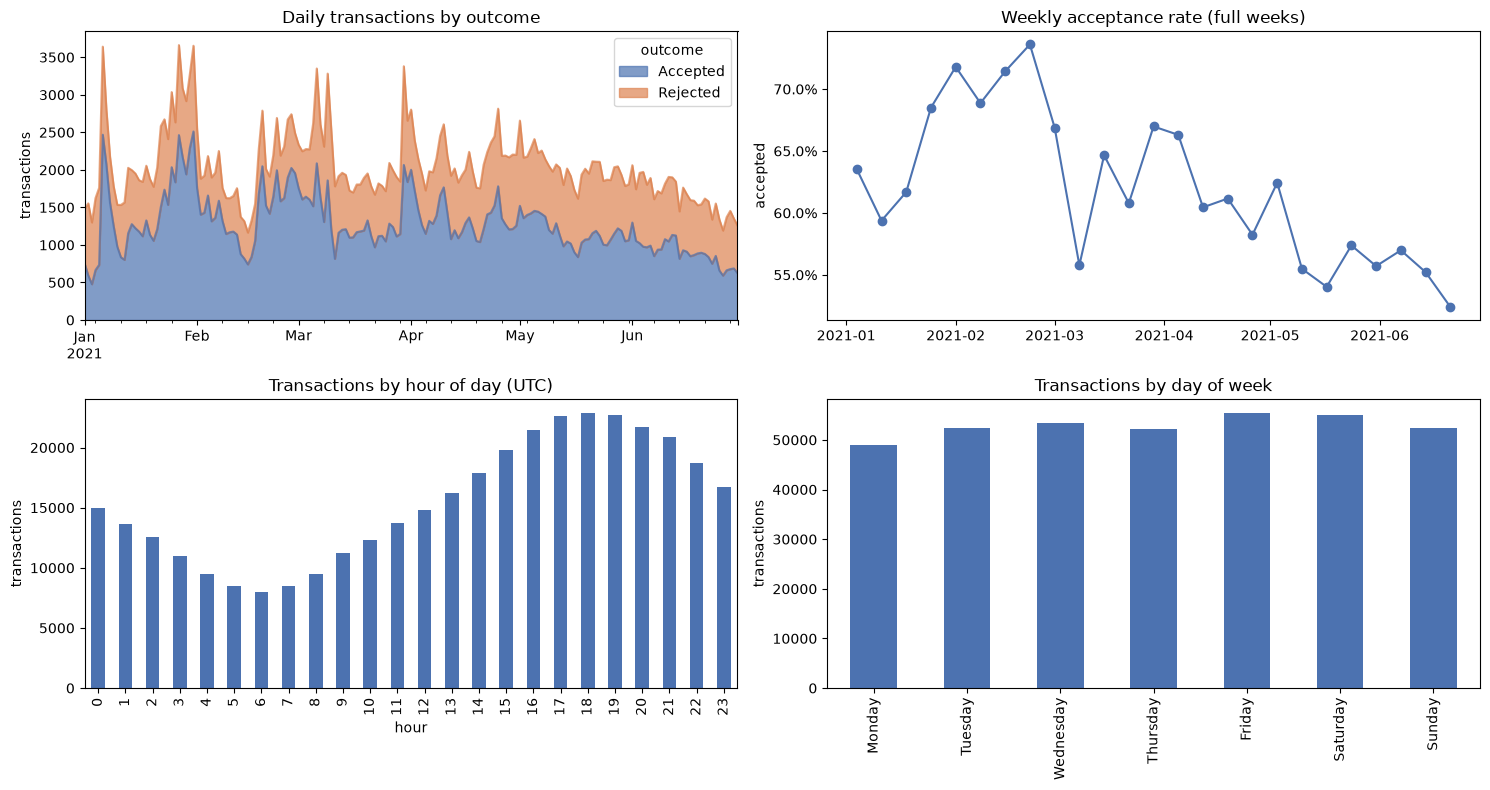

Weekly acceptance rate: min 52.4% (week of 21 Jun), max 73.6% (week of 22 Feb)


In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

tx["date"] = tx["ts"].dt.normalize()
tx["week"] = tx["ts"].dt.to_period("W").dt.start_time
tx["month"] = tx["ts"].dt.to_period("M")

tx["cb_on_accepted"] = tx["has_cb"] & tx["accepted"]
monthly_flow = tx.groupby("month").agg(
    transactions=("txId", "size"),
    users=("userId", "nunique"),
    accepted=("accepted", "sum"),
    chargebacks=("cb_on_accepted", "sum"),
)
monthly_flow.index = monthly_flow.index.astype(str)
monthly_flow.loc["total"] = monthly_flow.sum()
monthly_flow["rejected_%"] = ((1 - monthly_flow["accepted"] / monthly_flow["transactions"]) * 100).round(1)
monthly_flow["chargeback_%_of_accepted"] = (monthly_flow["chargebacks"] / monthly_flow["accepted"] * 100).round(2)
display(monthly_flow[["transactions", "users", "rejected_%", "accepted", "chargebacks", "chargeback_%_of_accepted"]])

full_weeks = tx.groupby("week")["date"].nunique().loc[lambda s: s == 7].index
weekly_acceptance = tx[tx["week"].isin(full_weeks)].groupby("week")["accepted"].mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
tx.groupby(["date", "outcome"]).size().unstack().plot.area(
    ax=axes[0, 0], alpha=.7, color={"Accepted": "#4C72B0", "Rejected": "#DD8452"})
axes[0, 0].set(title="Daily transactions by outcome", xlabel="", ylabel="transactions")
axes[0, 1].plot(weekly_acceptance.index, weekly_acceptance.values, marker="o", color="#4C72B0")
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0, 1].set(title="Weekly acceptance rate (full weeks)", xlabel="", ylabel="accepted")
tx["ts"].dt.hour.value_counts().sort_index().plot.bar(ax=axes[1, 0], color="#4C72B0")
axes[1, 0].set(title="Transactions by hour of day (UTC)", xlabel="hour", ylabel="transactions")
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
tx["ts"].dt.day_name().value_counts().reindex(WEEKDAYS).plot.bar(ax=axes[1, 1], color="#4C72B0")
axes[1, 1].set(title="Transactions by day of week", xlabel="", ylabel="transactions")
plt.tight_layout()
plt.show()

print(f"Weekly acceptance rate: min {weekly_acceptance.min():.1%} (week of {weekly_acceptance.idxmin():%d %b}), "
      f"max {weekly_acceptance.max():.1%} (week of {weekly_acceptance.idxmax():%d %b})")

**Results.**

1. **Volume.** There are 49 to 70 thousand transactions per month, the most in January and the fewest in June. From May the volume gradually goes down.

2. **The strictness of the existing system is not stable.** The rejection rate is lowest in February (28.3%), highest in June (45.4%), and 37.9% over the whole period. By week, the acceptance rate ranges from 52.4% to 73.6%.

3. **The chargeback rate among accepted transactions rose sharply:** it is 0.42% in January, 1.26% in February and 2.13% in March, which is the maximum. After that it stays between 1.44 and 1.71 percent. Over the whole period it is 1.39%.

4. **An interesting coincidence.** It was in February, when the system rejected the fewest transactions, that the chargeback rate rose sharply. In the following months rejection became stricter, but the chargeback rate never returned to the January level. This suggests that the existing system does not separate fraud accurately: it rejects more, but the fraud rate still stays high. This is exactly where a model can add value.

5. **Daily rhythm.** The minimum is at 6 in the morning (UTC), the peak is from 17 to 19 in the evening. The difference between weekdays is small.

6. **What this means for the model.** The population of accepted transactions, on which we observe fraud, changes over time, because both the activity of the fraudsters and what the existing system lets through change. This is the first argument for splitting train and test by time.

### 1.5 Column dictionary

Below are all the original columns with their type, fill rate, number of unique values and an example. The next cell describes the meaning of each one.

In [6]:
RAW_COLUMNS = ["eventTimestamp", "txId", "userId", "outcome", "price", "productQuantity", "product", "productType",
               "paymentMethodType", "paymentMethodIssuer", "paymentMethodCountryCode", "ipCountryCode", "emailDomain"]
display(pd.DataFrame({
    "dtype": tx[RAW_COLUMNS].dtypes.astype(str),
    "non_null": tx[RAW_COLUMNS].notna().sum(),
    "n_unique": tx[RAW_COLUMNS].nunique(),
    "example": tx[RAW_COLUMNS].iloc[2],
}))

,dtype,non_null,n_unique,example
eventTimestamp,float64,369853,369842,1609459373454.0
txId,str,369853,369853,6bc992904bc411eb82ecf2f121893eb6
userId,str,369853,231461,5371aa58-4bc3-11eb-844d-5e16b4d7fead
outcome,str,369853,2,Accepted
price,float64,369853,18970,2.13
productQuantity,float64,369853,10,1.0
product,str,369853,11319,PayDay 2 Steam Key GLOBAL
productType,str,369853,6,game
paymentMethodType,str,369853,2,creditCard
paymentMethodIssuer,str,355578,4110,OTPBANK-HU


**Meaning of the columns**

**a) Content of the transaction**

1. `price`: the value of the order. The currency is not specified.
2. `productQuantity`: the number of units in the order, from one to ten.
3. `product`: the product name, 11,319 unique values. It cannot go into the model directly and needs processing.
4. `productType`: the product category, six classes: giftcard, game, dlc, game_points, subscription, software.

**b) Payment and buyer**

1. `paymentMethodType`: the payment method, creditCard or paypal.
2. `paymentMethodIssuer`: the bank that issued the card, PAYPAL in the case of PayPal; the country code is appended at the end. 4,110 unique values.
3. `paymentMethodCountryCode`: the country of the card or the PayPal account.
4. `ipCountryCode`: the country determined from the buyer's IP address. Comparing these two gives a mismatch signal.
5. `emailDomain`: the domain of the buyer's email, 6,789 unique values.

**c) Identifiers and time**

1. `txId`: the transaction identifier, unique.
2. `userId`: the user identifier. It is not suitable as a feature, because the model would memorize the specific user; but it is necessary for computing the user's history.
3. `eventTimestamp`: the time of the event in milliseconds. In a transaction row this is the time of the purchase, and in a chargeback row it is the time of the notification.

**d) Outcome**

1. `outcome`: the decision of the existing system, Accepted or Rejected. This is not what the model predicts: we are interested in real fraud and not in repeating the decision of the old system. It is not suitable as a feature either, because the model will work in the place of exactly this decision.
2. The fact and the time of the chargeback, which appear after the transaction. The target is built from this; using it as a feature would be leakage.

`txId` and `userId` have additional information embedded in them, which we discuss in 3.2.

## 2. Chargebacks and defining the target

### 2.1 How long it takes for a chargeback to arrive

In the first part we saw that chargebacks arrive later than the transactions. Now we measure this: for each chargeback we compute the delay, the time from the transaction to the notification, and look at its distribution. This determines how long we have to wait before we treat a transaction as clean.

Chargebacks: 3,220   negative delays: 0


,delay_days
count,3220.00
mean,17.39
std,21.53
min,0.00
10%,0.33
25%,3.63
50%,10.91
75%,21.29
90%,42.35
95%,63.97


,chargebacks,%,cumulative_%
cb_delay_days,,,
<1d,476,14.8,14.8
1..7d,704,21.9,36.7
7..14d,811,25.2,61.9
14..30d,710,22.0,83.9
30..60d,345,10.7,94.6
60..90d,102,3.2,97.8
>90d,72,2.2,100.0


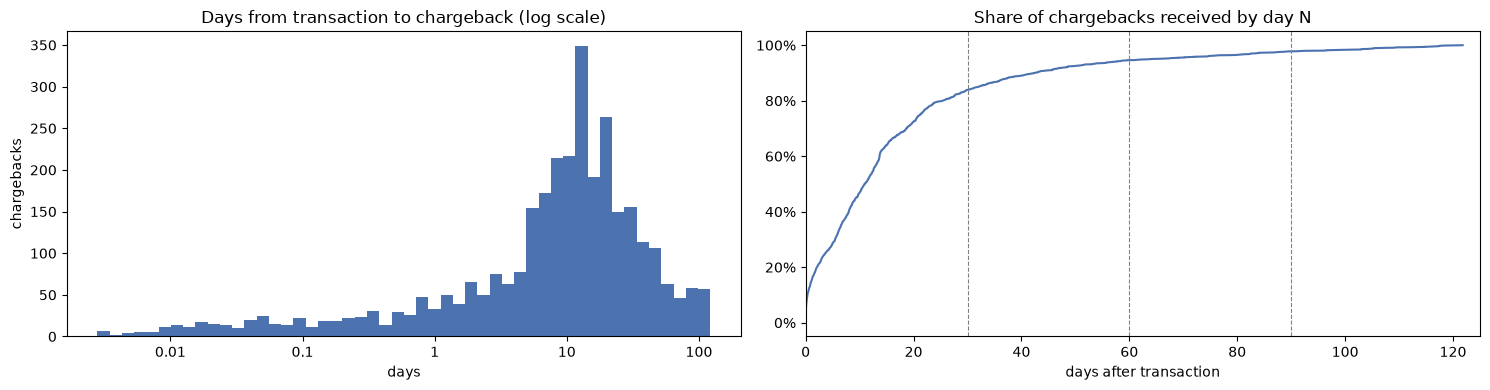

In [7]:
tx["cb_delay_days"] = (tx["cb_ts"] - tx["ts"]).dt.total_seconds() / 86400
delays = tx.loc[tx["has_cb"], "cb_delay_days"]
print(f"Chargebacks: {len(delays):,}   negative delays: {(delays < 0).sum()}")
display(delays.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2).to_frame("delay_days"))

buckets = pd.cut(delays, [0, 1, 7, 14, 30, 60, 90, np.inf],
                 labels=["<1d", "1..7d", "7..14d", "14..30d", "30..60d", "60..90d", ">90d"])
bucket_table = buckets.value_counts().sort_index().to_frame("chargebacks")
bucket_table["%"] = (bucket_table["chargebacks"] / len(delays) * 100).round(1)
bucket_table["cumulative_%"] = bucket_table["%"].cumsum().round(1)
display(bucket_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(np.log10(delays.clip(lower=1e-3)), bins=50, color="#4C72B0")
axes[0].set_xticks([-2, -1, 0, 1, 2], ["0.01", "0.1", "1", "10", "100"])
axes[0].set(title="Days from transaction to chargeback (log scale)", xlabel="days", ylabel="chargebacks")
ecdf = np.sort(delays.to_numpy())
axes[1].plot(ecdf, np.arange(1, len(ecdf) + 1) / len(ecdf), color="#4C72B0")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
for day in [30, 60, 90]:
    axes[1].axvline(day, color="grey", ls="--", lw=.8)
axes[1].set(title="Share of chargebacks received by day N", xlabel="days after transaction", xlim=(0, 125))
plt.tight_layout()
plt.show()

**Results.**

1. **There are no negative delays**, every chargeback follows its transaction. This is one more confirmation that the join is correct.

2. **The distribution has a long right tail.** The median is 10.9 days, the mean is 17.4, the 90th percentile is 42.4, the 99th percentile is 106.6 and the maximum is 121.8 days. This last number matches the dispute window of the card networks.

3. **Cumulatively:** 14.8% arrive within one day, 36.7% within a week, 61.9% within two weeks, 83.9% within 30 days, 94.6% within 60 days and 97.8% within 90 days.

4. **Shape.** On a logarithmic scale the main mass is between 5 and 30 days, and on the left a long flat tail goes down to a few minutes. A formal bank dispute is unlikely at that speed; this looks more like early notifications. We will check this by payment method.

5. **Business conclusion.** More than half of the chargebacks arrive within two weeks, but one in twenty arrives after more than two months. So the company does not know the scale of fraud in real time, and assessing the result of a month takes at least a month and a half.

### 2.2 Delay by payment method and product

Above we looked at the delay across all chargebacks together. For defining the target it matters whether the chargeback arrives the same way for different payment methods: if one group is much slower, the waiting window has to fit that group. We compute the shares on the January to March transactions, which had more than 137 days before the extraction, more than the maximum delay we have seen.

,count,mean,50%,90%,max
paymentMethodType,,,,,
creditCard,1931.0,23.0,14.4,49.5,121.8
paypal,1289.0,9.1,2.7,25.5,120.0


,within 3d %,within 7d %,within 14d %,within 30d %,within 60d %,within 90d %
Jan to Mar reference,,,,,,
creditCard,0.8,13.7,52.3,83.2,93.5,96.5
paypal,57.8,74.0,86.5,93.4,98.2,99.7


,count,50%,90%
productType,,,
game,1886.0,10.0,33.8
giftcard,924.0,11.2,56.2
game_points,193.0,23.5,57.5
dlc,171.0,13.3,57.9
subscription,43.0,0.8,17.0
software,3.0,11.1,71.6


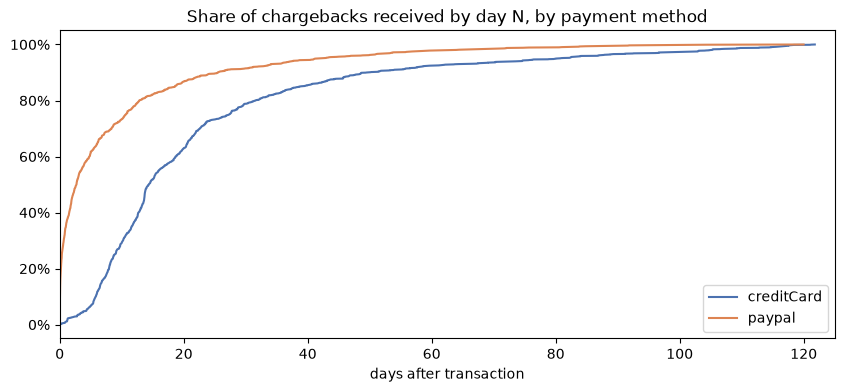

In [8]:
cbs = tx[tx["has_cb"]]
display(cbs.groupby("paymentMethodType")["cb_delay_days"].describe(percentiles=[.5, .9])[["count", "mean", "50%", "90%", "max"]].round(1))

reference_cbs = cbs[cbs["ts"] < pd.Timestamp(2021, 4, 1)]
display(pd.DataFrame({
    method: {f"within {h}d %": (group["cb_delay_days"] <= h).mean() * 100 for h in [3, 7, 14, 30, 60, 90]}
    for method, group in reference_cbs.groupby("paymentMethodType")
}).T.round(1).rename_axis("Jan to Mar reference"))

display(cbs.groupby("productType")["cb_delay_days"].describe(percentiles=[.5, .9])[["count", "50%", "90%"]]
        .sort_values("count", ascending=False).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for method, color in [("creditCard", "#4C72B0"), ("paypal", "#DD8452")]:
    d = np.sort(cbs.loc[cbs["paymentMethodType"] == method, "cb_delay_days"].to_numpy())
    ax.plot(d, np.arange(1, len(d) + 1) / len(d), label=method, color=color)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="Share of chargebacks received by day N, by payment method", xlabel="days after transaction", xlim=(0, 125))
ax.legend()
plt.show()

**Results.**

1. **The payment method changes the delay a lot.** The median for a card chargeback is 14.4 days and the 90th percentile is 49.5 days. The PayPal median is only 2.7 days and the 90th percentile is 25.5 days.

2. **In the full picture**, only 0.8% of card chargebacks arrive within three days, 13.7% within a week, 83.2% within 30 days, 93.5% within 60 days and 96.5% within 90 days. On PayPal 57.8% already arrive within three days, 93.4% within 30 days and 98.2% within 60 days. On cards almost no chargebacks arrive in the first days, which matches the bank dispute process; on PayPal most of them show up in the very first days. It is PayPal that explains the fast tail seen in the previous cell.

3. **By product**, the fastest are subscriptions (median 0.8 days, although there are only 43 cases) and the slowest is in-game currency (23.5 days). Gift cards and DLC have a long tail, with a 90th percentile of 56 to 58 days.

4. **What this means for the target.** The waiting window has to fit the slowest group, the cards. A 60 day window covers 93.5% of card chargebacks, and a 90 day window covers 96.5%.

5. **Business conclusion.** PayPal disputes are visible almost immediately, so they are the fastest signal for monitoring the model: they reveal the start of a new wave in days instead of weeks.

### 2.3 How complete the chargebacks of the last months are

We take the delay curve of the January to March transactions as the reference and use it to estimate what share of each month's chargebacks should already be visible. This tells us how far we can trust the label of the last months.

In [9]:
reference = np.sort(reference_cbs["cb_delay_days"].to_numpy())
arrival_share = lambda days: np.searchsorted(reference, np.asarray(days, dtype=float), side="right") / len(reference)

horizons = [7, 14, 30, 45, 60, 90, 120]
display(pd.Series(arrival_share(horizons) * 100, index=horizons, name="% arrived (Jan to Mar reference)")
        .round(1).rename_axis("days after transaction").to_frame())

tx["days_until_extract"] = (EXTRACT_DATE - tx["ts"]).dt.total_seconds() / 86400
monthly_labels = tx.groupby("month").agg(
    transactions=("txId", "size"),
    chargebacks=("has_cb", "sum"),
    min_days_observed=("days_until_extract", "min"),
    max_days_observed=("days_until_extract", "max"),
)
monthly_labels["cb_after_60d_%"] = cbs.groupby("month")["cb_delay_days"].apply(lambda s: (s > 60).mean() * 100)
monthly_labels["expected_completeness_%"] = tx.groupby("month")["days_until_extract"].apply(lambda s: arrival_share(s).mean() * 100)
display(monthly_labels.round(1))

,% arrived (Jan to Mar reference)
days after transaction,
7,26.4
14,59.5
30,85.4
45,91.2
60,94.5
90,97.2
120,99.9


,transactions,chargebacks,min_days_observed,max_days_observed,cb_after_60d_%,expected_completeness_%
month,,,,,,
2021-01,70094,190,196.0,227.0,9.5,100.0
2021-02,56062,506,168.0,196.0,4.2,100.0
2021-03,66945,891,137.0,168.0,5.4,100.0
2021-04,64685,648,107.0,137.0,11.4,99.7
2021-05,62958,527,76.0,107.0,1.9,97.3
2021-06,49109,458,46.0,76.0,0.7,94.6


**Results.**

1. **The reference curve:** 26.4% of chargebacks arrive within 7 days, 59.5% within 14 days, 85.4% within 30 days, 94.5% within 60 days, 97.2% within 90 days and 99.9% within 120 days.

2. **The label of the last months is incomplete.** The June transactions had only 46 to 76 days before the extraction, so the expected completeness is 94.6%, for May 97.3% and for April 99.7%. So for the last months about 3 to 5 percent of the chargebacks are not visible yet.

3. **This is an estimate and not an exact number.** We assume that the delay is similar in every month, but the data partly breaks this assumption. The share of chargebacks that arrived after 60 days is 4.2% in February, 5.4% in March, 9.5% in January and 11.4% in April. Some months have a heavier tail, so the real completeness of the last months may be lower than shown. The low figures for May and June (1.9% and 0.7%) are explained by the fact that we could not observe them for more than 60 days.

4. **What this means for the target.** We treat a transaction without a chargeback as clean only if it had enough time to receive a chargeback. Otherwise we would label the fraudulent transactions of the last weeks as clean and teach the model to ignore exactly the most recent patterns.

### 2.4 Behavior of users with chargebacks

We have one more question: is fraud a property of one transaction or of the user? Let's see what the users with at least one chargeback do: how many chargebacks they have, when their rejected attempts happen and what happens to their other accepted transactions.

In [10]:
cb_users = tx.loc[tx["has_cb"], "userId"].unique()
cb_per_user = tx[tx["has_cb"]].groupby("userId").size()
print(f"Users with at least one chargeback: {len(cb_users):,}   with more than one: {(cb_per_user > 1).sum():,}")
display(cb_per_user.value_counts().sort_index().rename_axis("chargebacks per user").to_frame("users").head(8))

firsts = tx[tx["has_cb"]].groupby("userId").agg(first_cb_tx=("ts", "min"), first_alert=("cb_ts", "min"))
fraud_user_tx = tx[tx["userId"].isin(cb_users)].merge(firsts, on="userId")

rejected_attempts = fraud_user_tx[~fraud_user_tx["accepted"]]
within_24h = ((rejected_attempts["ts"] - rejected_attempts["first_cb_tx"]).abs() <= pd.Timedelta(days=1)).sum()
print(f"Rejected attempts by these users: {len(rejected_attempts):,}   within 24h of their first chargeback transaction: {within_24h:,}")

other_accepted = fraud_user_tx[fraud_user_tx["accepted"] & ~fraud_user_tx["has_cb"]]
display(pd.Series({
    "before the first chargeback transaction": (other_accepted["ts"] < other_accepted["first_cb_tx"]).sum(),
    "between the first chargeback transaction and the first alert":
        ((other_accepted["ts"] >= other_accepted["first_cb_tx"]) & (other_accepted["ts"] < other_accepted["first_alert"])).sum(),
    "after the first alert": (other_accepted["ts"] >= other_accepted["first_alert"]).sum(),
}, name="accepted transactions without own chargeback").to_frame())

after_alert = fraud_user_tx[fraud_user_tx["ts"] >= fraud_user_tx["first_alert"]]
print(f"Transactions of these users after their first alert: {len(after_alert)}   accepted: {after_alert['accepted'].sum()}")

Users with at least one chargeback: 2,559   with more than one: 370


,users
chargebacks per user,
1,2189
2,259
3,63
4,17
5,5
6,12
7,4
8,4


Rejected attempts by these users: 1,639   within 24h of their first chargeback transaction: 925


,accepted transactions without own chargeback
before the first chargeback transaction,109
between the first chargeback transaction and the first alert,97
after the first alert,0


Transactions of these users after their first alert: 38   accepted: 0


**Results.**

1. **2,559 users have a chargeback.** Of these, 2,189 have one and 370 have more than one. A few users have six to eight chargebacks.

2. **Attempts become more frequent around the moment of fraud.** These users have 1,639 rejected attempts, 925 of them within 24 hours of the first transaction with a chargeback. So what sets them apart is not the number of rejections but their concentration in time. This is an important hint for features: how many attempts and rejections the user had in the last hours.

3. **Their other accepted transactions have no chargeback of their own**, there are 206 such transactions in total. 109 were made before the first transaction with a chargeback, 97 between it and the first notification, and none after the notification. In general, after the first notification these users have 38 attempts and none of them was accepted. This is consistent with the idea that the account is blocked after a chargeback.

4. **What this means for the target.** Fraud is not only a property of one transaction, it also has a user dimension. It is an open question whether we should treat some of these 206 transactions as fraud.

### 2.5 Decisions about the target

1. **The target is built only on accepted transactions, and the 33 anomalies go out together with the rest of the rejected ones.** We cannot observe the outcome of a rejected transaction: it is neither fraud nor clean. This is the well known selection bias problem, where the outcome is visible only for accepted cases, the same way loan repayment is visible only for loans that were granted. By labelling the rejected ones as fraud, the model would repeat the decisions of the old system, and by labelling them as clean we would have more than 140 thousand wrong labels. The 33 anomalies are 1% of the chargebacks and the cause is unknown.

2. **A transaction counts as clean if it had at least 60 days to receive a chargeback; the window is the same for both payment methods.** About 94.5% of chargebacks arrive within 60 days, 93.5% on cards. 90 days would raise the coverage on cards only to 96.5%, but the labelled data would end in mid May and the test set would shrink a lot. One window for both methods is used so that the definition of the label does not depend on the payment method. As a result, transactions made up to and including 16 June have a label, and transactions made from 17 June go out in both classes.

3. **Fraud is a chargeback that arrived within 60 days of the transaction.** This way every transaction has the same observation time for fraud to show up, just like the fixed outcome window in credit risk. If we counted a chargeback that arrived at any time, the January transactions would have 196 to 226 days and the June ones 60 to 75 days, and the old months would pick up additional, late fraud. Chargebacks that arrived after 60 days are counted neither as fraud nor as clean: we remove them from training and evaluation. They are fraud in reality, so with a 0 we would punish the model for scoring high exactly the transactions it should catch. Labelling them with a 1 would break the definition of the window. For comparison we also compute the variant with a chargeback at any time.

4. **We do not spread the fraud label to other transactions of the same user.** The organizer of the IEEE CIS competition (Vesta) spread fraud to the transactions made after the chargeback, but by linking card, email and address. We only have the user identifier. The 206 transactions seen above have no chargeback of their own, and labelling them as fraud would bring uncertainty into the label.

### 2.6 Building the target

We move the decisions into code. We show how many transactions are left after each filter, how many are fraud and how the fraud rate is distributed by month.

In [11]:
MATURITY_DAYS = 60
LABEL_CUTOFF = EXTRACT_DATE - pd.Timedelta(days=MATURITY_DAYS)

tx["is_mature"] = tx["ts"] < LABEL_CUTOFF
tx["late_cb"] = tx["has_cb"] & (tx["cb_delay_days"] > MATURITY_DAYS)
tx["in_target"] = tx["accepted"] & tx["is_mature"] & ~tx["late_cb"]
tx["is_fraud"] = (tx["has_cb"] & (tx["cb_delay_days"] <= MATURITY_DAYS)).astype(int)
tx["is_fraud_any_time"] = tx["has_cb"].astype(int)

display(pd.Series({
    "all transactions": len(tx),
    "minus rejected": -int((~tx["accepted"]).sum()),
    f"minus accepted on or after {LABEL_CUTOFF:%d %B} (not mature)": -int((tx["accepted"] & ~tx["is_mature"]).sum()),
    f"minus chargebacks after day {MATURITY_DAYS}": -int((tx["accepted"] & tx["is_mature"] & tx["late_cb"]).sum()),
    "in target": int(tx["in_target"].sum()),
}, name="transactions").to_frame())

labeled = tx[tx["in_target"]].copy()
any_time = tx[tx["accepted"] & tx["is_mature"]]
display(pd.DataFrame({
    "transactions": [len(labeled), len(any_time)],
    "fraud": [labeled["is_fraud"].sum(), any_time["is_fraud_any_time"].sum()],
    "fraud_%": [labeled["is_fraud"].mean() * 100, any_time["is_fraud_any_time"].mean() * 100],
}, index=[f"target: chargeback within {MATURITY_DAYS} days", "comparison: chargeback any time"]).round(2))

display(pd.DataFrame({
    "transactions": labeled.groupby("month").size(),
    "fraud": labeled.groupby("month")["is_fraud"].sum(),
    "fraud_%": (labeled.groupby("month")["is_fraud"].mean() * 100).round(2),
    "fraud_any_time_%": (any_time.groupby("month")["is_fraud_any_time"].mean() * 100).round(2),
}))

,transactions
all transactions,369853
minus rejected,-140283
minus accepted on or after 17 June (not mature),-10722
minus chargebacks after day 60,-174
in target,218674


,transactions,fraud,fraud_%
target: chargeback within 60 days,218674,2792,1.28
comparison: chargeback any time,218848,2966,1.36


,transactions,fraud,fraud_%,fraud_any_time_%
month,,,,
2021-01,43877,168,0.38,0.42
2021-02,40169,484,1.20,1.26
2021-03,41689,839,2.01,2.13
2021-04,40543,555,1.37,1.55
2021-05,36319,513,1.41,1.44
2021-06,16077,233,1.45,1.47


**Results.**

1. **218,674 transactions stay in the target.** Out of 369,853 we excluded 140,283 rejected ones (including the 33 with a chargeback), 10,722 accepted transactions that were made from 17 June and do not have a final label yet, and 174 transactions on which the chargeback arrived after 60 days.

2. **2,792 transactions were labelled as fraud, or 1.28%.** For comparison, with the chargeback at any time variant 2,966 out of 218,848 transactions would be fraud (1.36%). The difference is small, so the price of the fixed window is low.

3. **The fraud rate by month:** 0.38%, 1.20%, 2.01% (March, the maximum), 1.37%, 1.41%, 1.45%. The difference between the two variants is largest in April (1.37% and 1.55%) and January (0.38% and 0.42%), exactly the months with a heavy tail of late chargebacks. In May and June the variants are almost the same. The fixed window puts the months on equal terms and makes comparing months valid.

4. **The classes are heavily imbalanced**, about one fraud per 78 transactions.

## 3. Train and test split and data exploration

### 3.1 Time split

We split the transactions by time: train from 1 January through 30 April, test from 1 May through 16 June.

**Why by time and not at random.** The data changes a lot over time: the chargeback rate was 0.42% in January and 2.13% in March, and the rejection rate of the existing system ranges from 28.3% to 45.4%. With a random split the model would learn the patterns of a wave on transactions from the same wave, and the evaluation would come out better than reality. The time split asks exactly the question the business cares about: how will a model trained on the past work on future transactions.

**Why this date.** The test needs a period that has a matured label, up to 16 June. The February to March wave stays in train so that the model sees its patterns.

**A split by user (group split) is not needed.** It is needed with a random split, so that the model does not memorize a specific user. In a time split the test is the future, and having returning customers in it reflects real use. It is enough that we do not use `userId` as a feature. We check that the periods do not overlap and that the test does not contain transactions of already known fraudsters.

In [12]:
TEST_START = pd.Timestamp(2021, 5, 1)
labeled["split"] = np.where(labeled["ts"] < TEST_START, "train", "test")

split_summary = labeled.groupby("split").agg(
    first=("ts", "min"), last=("ts", "max"), transactions=("txId", "size"),
    fraud=("is_fraud", "sum"), fraud_pct=("is_fraud", "mean"),
).loc[["train", "test"]]
split_summary["fraud_pct"] = (split_summary["fraud_pct"] * 100).round(2)
split_summary["share_of_rows_pct"] = (split_summary["transactions"] / len(labeled) * 100).round(1)
display(split_summary)

train = labeled[labeled["split"] == "train"]
test = labeled[labeled["split"] == "test"]
assert train["ts"].max() < test["ts"].min()

first_alert = tx.loc[tx["has_cb"]].groupby("userId")["cb_ts"].min()
known_fraud_users = first_alert[first_alert < TEST_START].index
print(f"Test transactions from users already known as fraud before {TEST_START:%d %B}: "
      f"{test['userId'].isin(known_fraud_users).sum()}")

returning = test["userId"].isin(train["userId"])
display(pd.DataFrame({
    "transactions": [int(returning.sum()), int((~returning).sum())],
    "share_%": [returning.mean() * 100, (~returning).mean() * 100],
    "fraud": [int(test.loc[returning, "is_fraud"].sum()), int(test.loc[~returning, "is_fraud"].sum())],
    "fraud_%": [test.loc[returning, "is_fraud"].mean() * 100, test.loc[~returning, "is_fraud"].mean() * 100],
}, index=["user also seen in train", "user not seen in train"]).round(2))

,first,last,transactions,fraud,fraud_pct,share_of_rows_pct
split,,,,,,
train,2021-01-01 00:02:53.454,2021-04-30 23:59:23.107,166278,2046,1.23,76.0
test,2021-05-01 00:02:16.029,2021-06-16 23:59:57.218,52396,746,1.42,24.0


Test transactions from users already known as fraud before 01 May: 0


,transactions,share_%,fraud,fraud_%
user also seen in train,8649,16.51,55,0.64
user not seen in train,43747,83.49,691,1.58


**Results.**

1. **Train:** 166,278 transactions (76.0%), of which 2,046 are fraud (1.23%). **Test:** 52,396 transactions (24.0%), of which 746 are fraud (1.42%). The periods do not overlap.

2. **The test has not a single transaction from the users who were already known as fraud before 1 May.** So no additional filter is needed: it does not flatter the result.

3. **16.5% of the test comes from users who also appear in train.** This is expected and reflects real use. Interestingly, the fraud rate among them is 0.64%, and among new customers it is 1.58%: a new customer is two and a half times riskier. So when evaluating the quality of the model we will look at these two groups separately.

4. **The fraud rate in the test (1.42%) is slightly higher than the train average (1.23%).** The reason is that the very low January rate (0.38%) pulls the train average down. In the last months the rate is stable: 1.37% in April, 1.41% in May and 1.45% in June, so the test is at the level of the last train month.

### 3.2 Computed columns

Before analyzing the relationship with the target we prepare the computed columns. Everything is computed only from information that is known at the moment of the transaction.

1. **Account age.** `userId` is a version 1 UUID, which stores its creation time inside it (RFC 9562). We take this time as the moment the account was created and compute how old the account was at the time of purchase.
2. **Checkout duration.** `txId` is also a version 1 UUID. The difference between its creation time and `eventTimestamp` shows how long the order took before it was recorded.
3. **Unit price:** `price` divided by `productQuantity`.
4. **Country mismatch:** 1 if the IP country and the payment country are both known and do not match.
5. **Flags that the IP country or the issuer is unknown**, because the missing value itself may be informative.
6. **Hour and day of the week.**

We compute the columns on all transactions, including the rejected ones, because we will need them to compare the acceptance rate.

In [13]:
import uuid

UUID_EPOCH_OFFSET = 0x01B21DD213814000


def uuid1_time(values):
    ticks = values.map(lambda s: uuid.UUID(s).time).astype("int64")
    return pd.to_datetime((ticks - UUID_EPOCH_OFFSET) // 10, unit="us")


display(pd.DataFrame({
    "userId": tx["userId"].map(lambda s: uuid.UUID(s).version).value_counts(),
    "txId": tx["txId"].map(lambda s: uuid.UUID(s).version).value_counts(),
}).rename_axis("uuid version"))

tx["user_created"] = uuid1_time(tx["userId"])
tx["tx_created"] = uuid1_time(tx["txId"])
tx["account_age_days"] = (tx["ts"] - tx["user_created"]).dt.total_seconds() / 86400
tx["checkout_seconds"] = (tx["ts"] - tx["tx_created"]).dt.total_seconds()
tx["unit_price"] = tx["price"] / tx["productQuantity"]
both_countries = tx["ipCountryCode"].notna() & tx["paymentMethodCountryCode"].notna()
tx["country_mismatch"] = (both_countries & tx["ipCountryCode"].ne(tx["paymentMethodCountryCode"])).astype(int)
tx["ip_country_missing"] = tx["ipCountryCode"].isna().astype(int)
tx["issuer_missing"] = tx["paymentMethodIssuer"].isna().astype(int)
tx["hour"] = tx["ts"].dt.hour
tx["weekday"] = tx["ts"].dt.day_name()

print(f"Negative account ages: {(tx['account_age_days'] < 0).sum()}   negative checkout durations: {(tx['checkout_seconds'] < 0).sum()}")
print(f"Accounts created between {tx['user_created'].min():%d %B %Y} and {tx['user_created'].max():%d %B %Y}")
display(tx[["account_age_days", "checkout_seconds", "unit_price"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

AGE_BINS = [-np.inf, 10 / 1440, 1 / 24, 1, 7, 30, 90, 365, np.inf]
AGE_LABELS = ["under 10 min", "10 to 60 min", "1 h to 1 day", "1 to 7 days", "7 to 30 days",
              "30 to 90 days", "90 to 365 days", "over 1 year"]
display((pd.cut(tx["account_age_days"], AGE_BINS, labels=AGE_LABELS).value_counts(normalize=True).sort_index() * 100)
        .round(1).to_frame("% of transactions"))

display(pd.Series({
    "country_mismatch (of rows with both countries known)": tx.loc[both_countries, "country_mismatch"].mean() * 100,
    "ip_country_missing": tx["ip_country_missing"].mean() * 100,
    "issuer_missing": tx["issuer_missing"].mean() * 100,
}, name="% of transactions").round(2).to_frame())

DERIVED = ["user_created", "tx_created", "account_age_days", "checkout_seconds", "unit_price",
           "country_mismatch", "ip_country_missing", "issuer_missing", "hour", "weekday"]
labeled = labeled.join(tx[DERIVED])
train = labeled[labeled["split"] == "train"]
test = labeled[labeled["split"] == "test"]

,userId,txId
uuid version,,
1,369853,369853


Negative account ages: 0   negative checkout durations: 0
Accounts created between 25 November 2018 and 30 June 2021


,account_age_days,checkout_seconds,unit_price
count,369853.000,369853.000,369853.000
mean,65.992,130.481,26.592
std,140.180,212.390,34.296
min,0.000,5.812,0.094
10%,0.000,37.200,1.770
25%,0.001,56.662,6.450
50%,0.025,90.843,15.680
75%,48.413,147.478,33.200
90%,259.138,238.235,60.250
max,936.934,57500.746,2572.640


,% of transactions
account_age_days,
under 10 min,40.6
10 to 60 min,11.4
1 h to 1 day,6.7
1 to 7 days,6.3
7 to 30 days,7.1
30 to 90 days,7.5
90 to 365 days,14.7
over 1 year,5.8


,% of transactions
country_mismatch (of rows with both countries known),18.21
ip_country_missing,1.20
issuer_missing,3.86


**Results.**

1. **The identifiers contain time.** Every `userId` and `txId` is a version 1 UUID, so we extract the creation time of the account and of the order from them. There is no negative age or duration in any row, so the decoding is consistent. The accounts were created from 25 November 2018 to 30 June 2021.

2. **Account age splits into two groups.** 40.6% of purchases come from an account that was created less than 10 minutes earlier, and another 11.4% from an account aged ten to sixty minutes. So half of the buyers create the account right before the purchase. The second group is old customers: 14.7% have an account aged 90 days to one year, and 5.8% older than one year.

3. **Checkout duration:** the median is 91 seconds and 90% are under four minutes.

4. **Flags:** the IP and payment country do not match in 18.21% of cases, the IP country is unknown in 1.20% and the issuer in 3.86%.

5. **A limitation that has to be noted.** `checkout_seconds` and account age are computed with `eventTimestamp`. From the data we cannot tell whether it is written before the decision or after it. We come back to this assumption in the modelling part and measure its effect separately.

### 3.3 How to read the segment tables

The next part shows which variables separate fraud from clean transactions. We follow a few rules:

1. **The analysis is done only on train.** We do not touch the test before the evaluation, so that patterns seen on it do not sneak into the choice of the model.
2. **Every table has the same columns:** the number of transactions, the number of fraud cases, the fraud rate with a 95% confidence interval, the lift (how many times the rate of the segment is above or below the train average) and the acceptance rate of the existing system in this segment.
3. **We need the acceptance rate** because we see fraud only on accepted transactions. If the system rejects a large part of a segment, the transactions that reach us are already filtered and their fraud rate does not exactly reflect the whole segment.
4. **In high cardinality columns** (country, issuer, email domain) we show only the most frequent values, and the rest are merged into "other". Numeric columns are split into intervals. All boundaries and lists are defined on train only.

In [14]:
BASE_RATE = train["is_fraud"].mean()
train_period = tx[tx["ts"] < TEST_START].copy()
print(f"Train: {len(train):,} labeled transactions, {train['is_fraud'].sum():,} fraud, average fraud rate {BASE_RATE:.2%}")


def wilson_interval(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def segment_table(col, data=None, population=None):
    data = train if data is None else data
    population = train_period if population is None else population
    t = data.groupby(col, observed=True)["is_fraud"].agg(transactions="size", fraud="sum")
    low, high = wilson_interval(t["fraud"], t["transactions"])
    t["fraud_%"] = t["fraud"] / t["transactions"] * 100
    t["ci_low_%"] = np.clip(low * 100, 0, None)
    t["ci_high_%"] = high * 100
    t["lift"] = t["fraud"] / t["transactions"] / BASE_RATE
    t["acceptance_%"] = population.groupby(col, observed=True)["accepted"].mean() * 100
    return t.round(2)


def plot_rates(table, title):
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(table) + 1)))
    labels = [" / ".join(map(str, i)) if isinstance(i, tuple) else str(i) for i in table.index]
    rate = table["fraud_%"].to_numpy(dtype=float, copy=True)
    errors = np.vstack([rate - table["ci_low_%"].to_numpy(dtype=float), table["ci_high_%"].to_numpy(dtype=float) - rate])
    ax.barh(labels, rate, xerr=errors, color="#4C72B0", ecolor="grey", capsize=3)
    ax.axvline(BASE_RATE * 100, color="#C44E52", ls="--", lw=1, label=f"train average {BASE_RATE:.2%}")
    ax.invert_yaxis()
    ax.set(title=title, xlabel="fraud rate, %")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


def top_or_other(series, top_values):
    return series.where(series.isin(top_values), "other").where(series.notna(), "missing")


TOP_PM_COUNTRIES = train["paymentMethodCountryCode"].value_counts().head(15).index
TOP_IP_COUNTRIES = train["ipCountryCode"].value_counts().head(15).index
TOP_DOMAINS = train["emailDomain"].value_counts().head(10).index
TOP_ISSUERS = train["paymentMethodIssuer"].value_counts().head(15).index
DOMAIN_COUNTS = train["emailDomain"].value_counts()

PRICE_EDGES = [0, 5, 10, 15, 20, 30, 40, 60, 100, np.inf]
PRICE_LABELS = ["0..5", "5..10", "10..15", "15..20", "20..30", "30..40", "40..60", "60..100", "over 100"]
CHECKOUT_EDGES = train["checkout_seconds"].quantile([0, .2, .4, .6, .8, 1]).round().to_numpy(copy=True)
CHECKOUT_EDGES[0], CHECKOUT_EDGES[-1] = 0, np.inf
CHECKOUT_LABELS = ([f"{a:.0f}..{b:.0f} s" for a, b in zip(CHECKOUT_EDGES[:-2], CHECKOUT_EDGES[1:-1])]
                   + [f"over {CHECKOUT_EDGES[-2]:.0f} s"])
HOUR_LABELS = ["night 0..5", "morning 6..11", "afternoon 12..17", "evening 18..23"]


def add_eda_columns(frame):
    frame = frame.copy()
    frame["pm_country"] = top_or_other(frame["paymentMethodCountryCode"], TOP_PM_COUNTRIES)
    frame["ip_country"] = top_or_other(frame["ipCountryCode"], TOP_IP_COUNTRIES)
    frame["email_group"] = top_or_other(frame["emailDomain"], TOP_DOMAINS)
    frame["email_rare"] = frame["emailDomain"].map(DOMAIN_COUNTS).fillna(0).lt(10).astype(int)
    frame["issuer_group"] = top_or_other(frame["paymentMethodIssuer"], TOP_ISSUERS)
    frame["price_band"] = pd.cut(frame["price"], PRICE_EDGES, labels=PRICE_LABELS)
    frame["unit_price_band"] = pd.cut(frame["unit_price"], PRICE_EDGES, labels=PRICE_LABELS)
    frame["account_age_band"] = pd.cut(frame["account_age_days"], AGE_BINS, labels=AGE_LABELS)
    frame["new_account_10min"] = (frame["account_age_days"] < 10 / 1440).astype(int)
    frame["checkout_band"] = pd.cut(frame["checkout_seconds"], CHECKOUT_EDGES, labels=CHECKOUT_LABELS, include_lowest=True)
    frame["hour_group"] = pd.cut(frame["hour"], [-1, 5, 11, 17, 23], labels=HOUR_LABELS)
    frame["weekday"] = pd.Categorical(frame["weekday"], categories=WEEKDAYS, ordered=True)
    return frame


train = add_eda_columns(train)
train_period = add_eda_columns(train_period)
display(segment_table("month"))

Train: 166,278 labeled transactions, 2,046 fraud, average fraud rate 1.23%


,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
month,,,,,,,
2021-01,43877,168,0.38,0.33,0.45,0.31,62.62
2021-02,40169,484,1.20,1.10,1.32,0.98,71.69
2021-03,41689,839,2.01,1.88,2.15,1.64,62.35
2021-04,40543,555,1.37,1.26,1.49,1.11,62.79


**Results.** Train has 166,278 labelled transactions, with an average fraud rate of 1.23%. This will be the reference point: we compare every segment with it.

The four months are very different: the fraud rate is 0.38% in January (less than a third of the average), 1.20% in February, 2.01% in March (1.64 times the average) and 1.37% in April. So train contains both a calm period and the February to March wave. This is an important warning: some of the signals seen below may belong only to the wave and stop working in future months. We will check this separately.

### 3.4 Payment method and card issuer

In [15]:
display(segment_table("paymentMethodType"))
display(segment_table(["paymentMethodType", "issuer_missing"]))
display(segment_table("issuer_group").sort_values("transactions", ascending=False))

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
paymentMethodType,,,,,,,
creditCard,93749,1402,1.50,1.42,1.58,1.22,65.57
paypal,72529,644,0.89,0.82,0.96,0.72,63.31


transactions  fraud  fraud_%  ci_low_%  ci_high_%  lift  acceptance_%
paymentMethodType issuer_missing                                                                       
creditCard        0                      85287   1394     1.63      1.55       1.72  1.33         64.75
                  1                       8462      8     0.09      0.05       0.19  0.08         75.18
paypal            0                      72525    644     0.89      0.82       0.96  0.72         63.31
                  1                          4      0     0.00      0.00      48.99  0.00         50.00

                        transactions  fraud  fraud_%  ci_low_%  ci_high_%  lift  acceptance_%
issuer_group                                                                                 
other                          82872   1299     1.57      1.49       1.65  1.27         60.43
PAYPAL-DE                      16039    115     0.72      0.60       0.86  0.58         70.00
PAYPAL-US                      13743    112     0.81      0.68       0.98  0.66         61.23
missing                         8466      8     0.09      0.05       0.19  0.08         75.16
PAYPAL-GB                       8188     44     0.54      0.40       0.72  0.44         65.47
PAYPAL-ES                       5755    157     2.73      2.34       3.18  2.22         82.70
PAYPAL-FR                       5265     40     0.76      0.56       1.03  0.62         52.90
PAYPAL-IT                       3904     18     0.46      0.29       0.73  0.37         73.95
CHASEBANKUSANA-US               3887     19     0.49      0.

**Results.**

1. **Cards are riskier than PayPal:** the fraud rate is 1.50% on cards and 0.89% on PayPal. The acceptance rate is almost the same (65.6% and 63.3%), so the difference is not explained by the filter of the old system.

2. **A missing issuer is a strong safe signal.** On cards where the issuer is unknown, only 8 out of 8,462 transactions are fraud (0.09%), against 1.63% with an issuer, eighteen times less. The old system also accepts them more often (75.2%). The data does not show why the issuer is missing, most likely it is a specific type of card or channel, but the signal is clear.

3. **The issuer contains more information than the country.** Banks of the same country also differ a lot: in the US NAVY is at 5.20%, JPMorgan Chase at 1.95%, Wells Fargo at 1.74% and Chase USA at only 0.49%. PayPal Spain is at 2.73% and PayPal United Kingdom at 0.54%. Some large issuers had no fraud at all: Revolut (2,717 transactions), Piraeus Bank (2,157) and PayPal Poland (1,869). So the issuer is a valuable feature, but with 4,110 values we cannot use it directly.

### 3.5 Geography

            transactions  fraud  fraud_%  ci_low_%  ci_high_%  lift  acceptance_%
pm_country                                                                       
US                 47863    651     1.36      1.26       1.47  1.11         67.52
other              23064    230     1.00      0.88       1.13  0.81         47.45
GB                 21466     92     0.43      0.35       0.53  0.35         71.76
DE                 16737    146     0.87      0.74       1.02  0.71         68.05
CL                 11651     29     0.25      0.17       0.36  0.20         88.13
ES                  8291    164     1.98      1.70       2.30  1.61         77.47
FR                  6809     44     0.65      0.48       0.87  0.53         50.23
AU                  5547    256     4.62      4.09       5.20  3.75         57.33
IT                  5088     26     0.51      0.35       0.75  0.42         69.76
CA                  4912    362     7.37      6.67       8.13  5.99         62.24
GR              

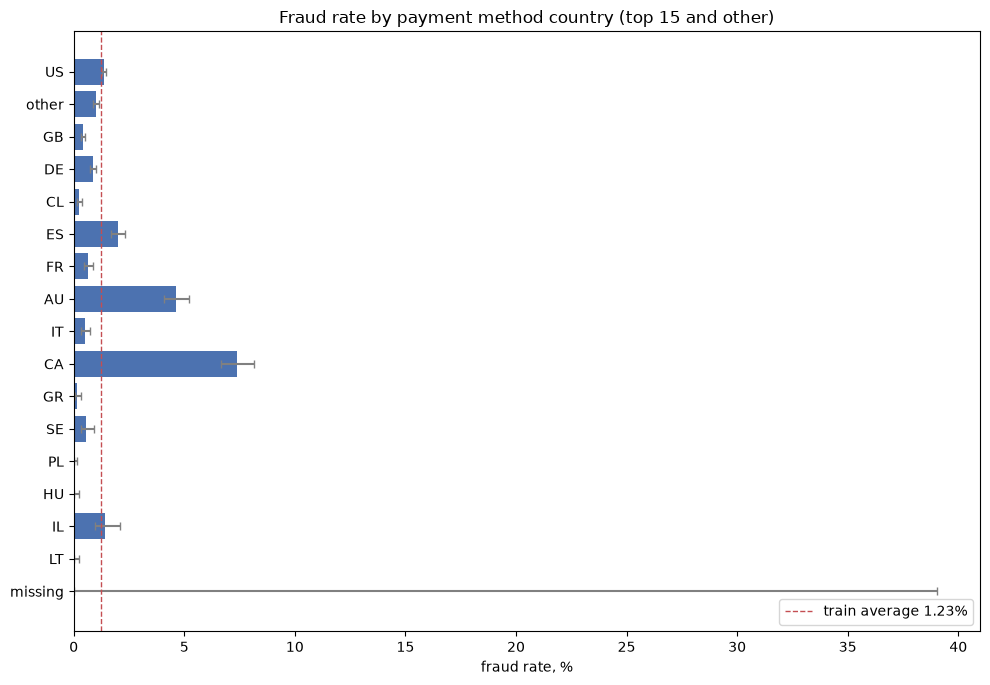

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
ip_country,,,,,,,
US,47270,273,0.58,0.51,0.65,0.47,73.71
other,26292,240,0.91,0.80,1.04,0.74,45.44
GB,18930,277,1.46,1.30,1.64,1.19,72.05
DE,16235,114,0.70,0.58,0.84,0.57,67.81
CL,11377,33,0.29,0.21,0.41,0.24,88.45
ES,7643,146,1.91,1.63,2.24,1.55,74.44
FR,6221,38,0.61,0.45,0.84,0.50,49.77
AU,5384,229,4.25,3.75,4.83,3.46,58.56
IT,5326,31,0.58,0.41,0.82,0.47,68.21


,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
country_mismatch,,,,,,,
0,148866,1484,1.00,0.95,1.05,0.81,68.96
1,17412,562,3.23,2.98,3.50,2.62,41.84


transactions  fraud  fraud_%  ci_low_%  ci_high_%  lift  acceptance_%
paymentMethodType country_mismatch                                                                       
creditCard        0                        82846    916     1.11      1.04       1.18  0.90         72.74
                  1                        10903    486     4.46      4.09       4.86  3.62         37.58
paypal            0                        66020    568     0.86      0.79       0.93  0.70         64.74
                  1                         6509     76     1.17      0.93       1.46  0.95         51.71

In [16]:
pm_countries = segment_table("pm_country").sort_values("transactions", ascending=False)
display(pm_countries)
plot_rates(pm_countries, "Fraud rate by payment method country (top 15 and other)")
display(segment_table("ip_country").sort_values("transactions", ascending=False))
display(segment_table("country_mismatch"))
display(segment_table(["paymentMethodType", "country_mismatch"]))

**Results.**

1. **The payment country is one of the strongest signals.** The fraud rate is 7.37% on Canadian cards (6 times the average), 4.62% on Australian ones and 1.98% on Spanish ones. At the other end are Chile (0.25%), Greece (0.14%), Hungary (0.04%), and Poland and Lithuania, where there was no fraud at all.

2. **The IP country gives additional information.** 10.68% is fraud from Canadian IPs and 3.02% from Israeli IPs. The contrast is interesting: it is 1.36% on US cards but only 0.58% from US IPs; 0.43% on UK cards and 1.46% from UK IPs. So what matters is not only the country, but the combination of card and IP. A missing IP country is also risky: 2.79%.

3. **Country mismatch:** 3.23%, against 1.00% on a match, three times more. The old system already rejects a large part of the mismatched transactions (acceptance 41.8%), but the risk stays high among the accepted ones too.

4. **The mismatch mostly works on cards.** On cards it is 4.46% with a mismatch and 1.11% with a match. On PayPal the difference is small: 1.17% and 0.86%. This makes sense, because the owner of a PayPal account often uses it from another country. The model has to capture this interaction, which tree models do by themselves.

### 3.6 Product

Besides the product type we also look at the product itself and check how concentrated fraud is. At the end we check whether all categories appear evenly over the whole period.

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
productType,,,,,,,
giftcard,78860,523,0.66,0.61,0.72,0.54,60.07
game,70601,1345,1.91,1.81,2.01,1.55,72.37
dlc,14097,115,0.82,0.68,0.98,0.66,66.91
game_points,1974,61,3.09,2.41,3.95,2.51,30.20
software,746,2,0.27,0.07,0.97,0.22,69.29


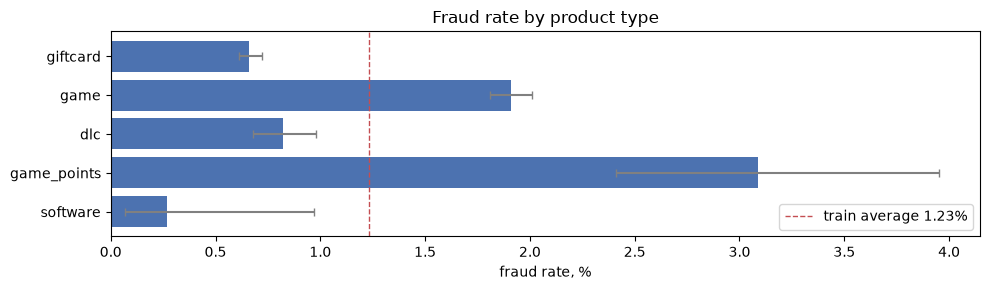

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
productQuantity,,,,,,,
1.0,132842,1933,1.46,1.39,1.52,1.18,62.54
2.0,8626,86,1.00,0.81,1.23,0.81,68.60
3.0,1491,17,1.14,0.71,1.82,0.93,58.78
4.0,913,2,0.22,0.06,0.80,0.18,59.13
5.0,705,2,0.28,0.08,1.03,0.23,58.85
6.0,508,4,0.79,0.31,2.01,0.64,64.68
7.0,382,0,0.00,0.00,1.00,0.00,75.49
8.0,461,0,0.00,0.00,0.83,0.00,77.35
9.0,308,0,0.00,0.00,1.23,0.00,73.16


,transactions,fraud,fraud_%
product,,,
FIFA 21 (ENG) Origin Key GLOBAL,682,258,37.83
Minecraft: Java Edition Official website Key GLOBAL,1521,127,8.35
Cyberpunk 2077 GOG Key GLOBAL,2006,102,5.08
HITMAN 3 Epic Games Key GLOBAL,110,76,69.09
Sea of Thieves: Anniversary Edition (PC/Xbox One) Xbox Key GLOBAL,284,69,24.30
HITMAN 3 Epic Games Key EUROPE,108,56,51.85
Watch Dogs: Legion Season Pass (DLC) Uplay Key EUROPE,59,52,88.14
Sea of Thieves (PC/Xbox One) Xbox Live Key GLOBAL,154,39,25.32
STAR WARS: Squadrons (Xbox One) Xbox Live Key GLOBAL,50,35,70.00


,fraud share %,transaction share %
top 10 products,41.5,12.7
top 20 products,52.8,13.9
top 50 products,66.7,17.6


Products in train: 8,610   with at least one fraud: 480
Test transactions whose product never appears in train: 8.1%


all transactions by product type,dlc,game,game_points,giftcard,software,subscription
month,,,,,,
2021-01,4768,24040,1595,39466,225,0
2021-02,3933,20068,1287,30580,194,0
2021-03,5464,27986,1694,31380,421,0
2021-04,6924,25529,2010,29984,238,0
2021-05,8971,24874,2327,26473,313,0
2021-06,7509,17750,2021,17346,249,4234


productType,giftcard,subscription
"products labeled subscription, split at 02 June 10:45",,
before first subscription,75867,0
from first subscription,0,4234


,most frequent subscription products
product,
PlayStation Plus Card 365 Days (USA) PSN Key UNITED STATES,689
Xbox Game Pass Ultimate - 7 Days Subscription (Xbox One/ Windows 10) Xbox Live Key GLOBAL,314
Xbox Game Pass Ultimate - 14 Days TRIAL Subscription (Xbox One/ Windows 10) Xbox Live Key GLOBAL,140
PlayStation Plus Card 90 Days (USA) PSN Key UNITED STATES,133
Suscripción PlayStation Plus Card 365 días (USA) código PSN Estados Unidos,120
Xbox Live Gold 12 months Xbox Live Key EUROPE,119


In [17]:
product_types = segment_table("productType").sort_values("transactions", ascending=False)
display(product_types)
plot_rates(product_types, "Fraud rate by product type")
display(segment_table("productQuantity"))

products = train.groupby("product")["is_fraud"].agg(transactions="size", fraud="sum")
products["fraud_%"] = (products["fraud"] / products["transactions"] * 100).round(2)
products = products.sort_values("fraud", ascending=False)
display(products.head(15))
display(pd.DataFrame({
    "fraud share %": [products["fraud"].head(n).sum() / products["fraud"].sum() * 100 for n in [10, 20, 50]],
    "transaction share %": [products["transactions"].head(n).sum() / len(train) * 100 for n in [10, 20, 50]],
}, index=["top 10 products", "top 20 products", "top 50 products"]).round(1))
print(f"Products in train: {len(products):,}   with at least one fraud: {(products['fraud'] > 0).sum():,}")
print(f"Test transactions whose product never appears in train: {(~test['product'].isin(products.index)).mean():.1%}")

display(pd.crosstab(tx["month"], tx["productType"]).rename_axis(columns="all transactions by product type"))
subscription = tx[tx["productType"] == "subscription"]
switch_moment = subscription["ts"].min()
same_products = tx[tx["product"].isin(subscription["product"])]
display(pd.crosstab(np.where(same_products["ts"] < switch_moment, "before first subscription", "from first subscription"),
                    same_products["productType"]).rename_axis(index=f"products labeled subscription, split at {switch_moment:%d %B %H:%M}"))
display(subscription["product"].value_counts().head(6).to_frame("most frequent subscription products"))

**Results.**

1. **Product type.** The fraud rate is 1.91% on games, 0.66% on gift cards and 0.82% on DLC. In-game currency is the riskiest, 3.09%, and on top of that the old system accepts it in only 30.2% of cases. So the accepted game_points are already strictly filtered and the real risk is even higher.

2. **Quantity.** It is 1.46% on single unit orders, and it does not exceed 0.8 percent on orders of four and more units. Among the 10 unit orders only 2 out of 20,042 are fraud. This is understandable: a fraudster buys one expensive key and not ten cheap ones.

3. **Fraud is concentrated on specific products.** Out of 8,610 products fraud happened on only 480. The top 10 products account for 41.5% of fraud, although they are only 12.7% of transactions; the top 50 account for 66.7% of fraud. Some products are almost entirely fraud: Watch Dogs: Legion Season Pass 88.1%, STAR WARS: Squadrons 70.0%, HITMAN 3 69.1%, FIFA 21 37.8%. At the same time it is only 0.22% on the best selling PlayStation Plus 365 day card. So the signal is at the product level and not only at the category level.

4. **8.1% of the test transactions are on a product that does not appear in train.** So the product level feature will need a neutral value for an unknown product.

5. **A data quality problem: the subscription category appears only from 2 June.** The change happened at one moment and completely: these products have 75,867 transactions before 10:45 on 2 June and all of them are giftcard, while from this moment all of them are subscription and none is giftcard any more. The products are subscriptions by nature: PlayStation Plus, Xbox Game Pass, Xbox Live Gold. So no new products appeared, the same products just had their category changed in the catalog. **Decision:** we turn subscription back into giftcard everywhere, keeping the classification on which the model learns.

### 3.7 Price

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
price_band,,,,,,,
0..5,21821,43,0.20,0.15,0.27,0.16,70.45
5..10,33174,57,0.17,0.13,0.22,0.14,71.64
10..15,27295,81,0.30,0.24,0.37,0.24,68.08
15..20,14180,82,0.58,0.47,0.72,0.47,66.64
20..30,24246,641,2.64,2.45,2.85,2.15,65.12
30..40,17359,392,2.26,2.05,2.49,1.84,69.42
40..60,16629,480,2.89,2.64,3.15,2.35,63.77
60..100,8258,158,1.91,1.64,2.23,1.55,48.56
over 100,3316,112,3.38,2.81,4.05,2.74,24.51


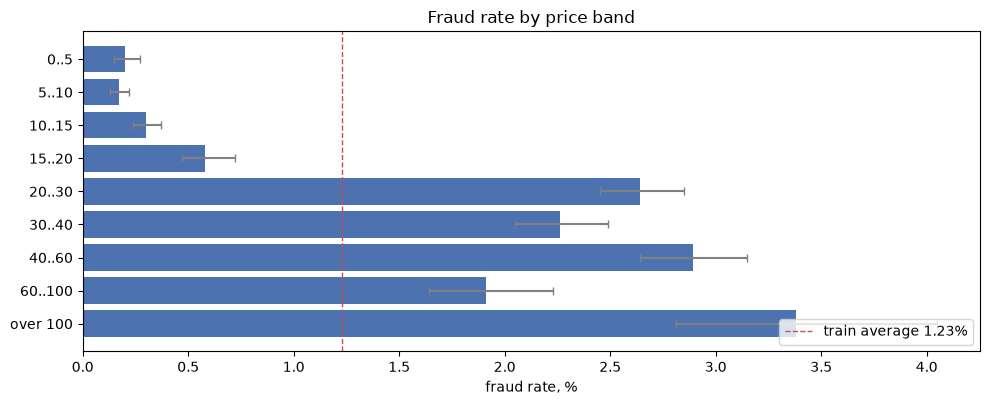

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
unit_price_band,,,,,,,
0..5,42965,45,0.10,0.08,0.14,0.09,74.70
5..10,24266,63,0.26,0.20,0.33,0.21,68.83
10..15,22060,82,0.37,0.30,0.46,0.30,64.95
15..20,12636,81,0.64,0.52,0.80,0.52,64.94
20..30,25839,655,2.53,2.35,2.73,2.06,66.27
30..40,18537,418,2.25,2.05,2.48,1.83,70.60
40..60,13002,495,3.81,3.49,4.15,3.09,57.16
60..100,5419,139,2.57,2.18,3.02,2.08,39.44
over 100,1554,68,4.38,3.47,5.51,3.56,16.27


,value
fraud share of transactions %,1.23
fraud share of value %,2.13
"median price, fraud",33.56
"median price, not fraud",15.01


In [18]:
price_bands = segment_table("price_band")
display(price_bands)
plot_rates(price_bands, "Fraud rate by price band")
display(segment_table("unit_price_band"))

fraud_mask = train["is_fraud"] == 1
display(pd.Series({
    "fraud share of transactions %": fraud_mask.mean() * 100,
    "fraud share of value %": train.loc[fraud_mask, "price"].sum() / train["price"].sum() * 100,
    "median price, fraud": train.loc[fraud_mask, "price"].median(),
    "median price, not fraud": train.loc[~fraud_mask, "price"].median(),
}).round(2).to_frame("value"))

**Results.**

1. **The relationship between price and fraud is not linear.** On orders up to 20 units of currency the fraud rate is 0.17% to 0.58%. In the 20 to 30 band it jumps to 2.64% and stays between 2.3 and 2.9 percent up to 60. On orders above 100 it is 3.38%, although the old system accepts them in only 24.5% of cases. This nonlinear shape matters: a linear model would not capture it.

2. **The unit price separates even more clearly.** On units priced up to 5 the fraud rate is 0.10%, from 40 to 60 it is 3.81% and above 100 it is 4.38%. So what matters is the value of the item itself and not the order total.

3. **Fraud is heavier by value than by count.** Fraud is 1.23% of transactions but 2.13% of the value. The median price of a fraud order is 33.56 and of a clean one 15.01. So when evaluating the model we will also look at the value of the fraud caught and not only the count: for the business one expensive caught order is worth three cheap ones.

### 3.8 Account age and checkout duration

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
account_age_band,,,,,,,
under 10 min,82129,1588,1.93,1.84,2.03,1.57,73.11
10 to 60 min,15095,114,0.76,0.63,0.91,0.61,51.97
1 h to 1 day,7903,53,0.67,0.51,0.88,0.55,46.39
1 to 7 days,7090,83,1.17,0.95,1.45,0.95,46.23
7 to 30 days,9467,61,0.64,0.50,0.83,0.52,55.84
30 to 90 days,11089,56,0.51,0.39,0.66,0.41,62.15
90 to 365 days,23973,77,0.32,0.26,0.40,0.26,66.58
over 1 year,9532,14,0.15,0.09,0.25,0.12,73.48


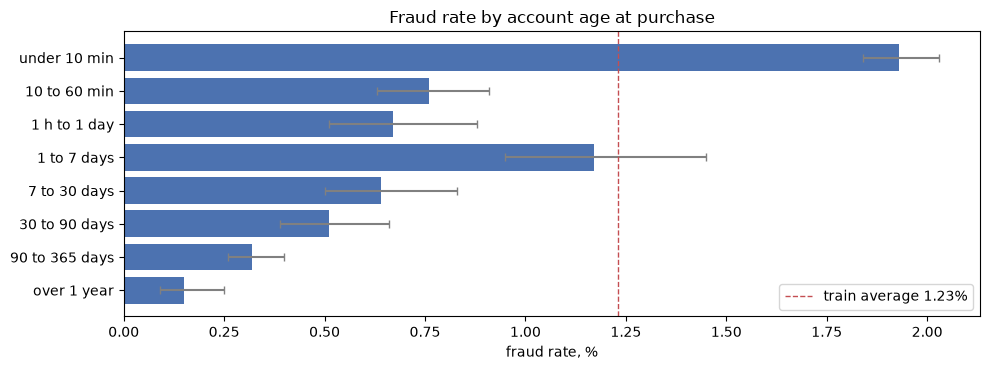

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
checkout_band,,,,,,,
0..51 s,33122,348,1.05,0.95,1.17,0.85,59.01
51..79 s,33874,509,1.50,1.38,1.64,1.22,63.34
79..112 s,32476,361,1.11,1.00,1.23,0.90,66.13
112..171 s,33616,397,1.18,1.07,1.30,0.96,67.98
over 171 s,33190,431,1.30,1.18,1.43,1.06,67.23


In [19]:
account_age = segment_table("account_age_band")
display(account_age)
plot_rates(account_age, "Fraud rate by account age at purchase")
display(segment_table("checkout_band"))

**Results.**

1. **Account age is a strong signal.** On accounts younger than 10 minutes the fraud rate is 1.93%, 1.57 times the average, and this is half of train. The risk goes down consistently with age: 0.32% from 90 days to one year and 0.15% on accounts older than one year, thirteen times less.

2. **The old system accepts new accounts most often**, in 73.1% of cases, while accounts aged 10 minutes to one week are accepted in only 46 to 52 percent. So it either does not use account age or uses it the other way round. This is a clear opportunity for the new model.

3. **Checkout duration is a weak signal.** Across the five groups the fraud rate ranges from 1.05% to 1.50%, with no clear direction. We will include it in the model but do not expect a large contribution.

### 3.9 Time and email domain

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
hour_group,,,,,,,
night 0..5,31093,310,1.00,0.89,1.11,0.81,65.61
morning 6..11,27306,469,1.72,1.57,1.88,1.40,62.53
afternoon 12..17,50990,685,1.34,1.25,1.45,1.09,64.29
evening 18..23,56889,582,1.02,0.94,1.11,0.83,65.27


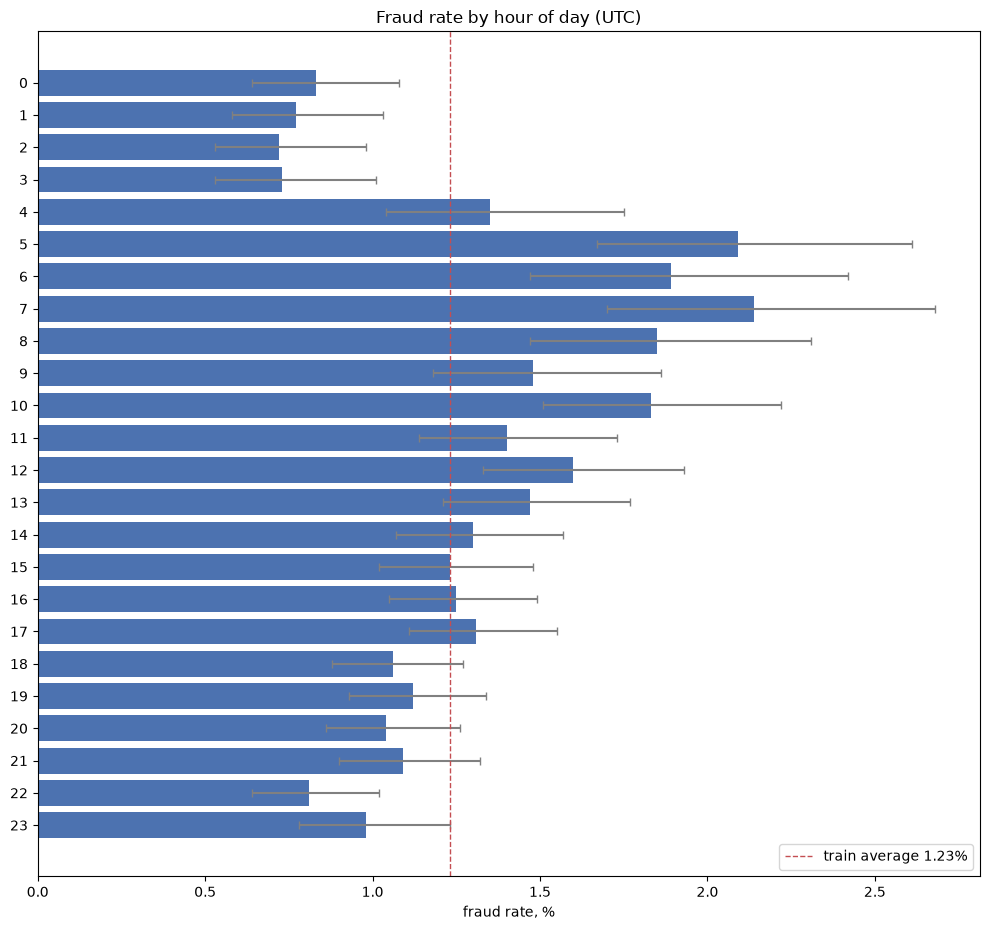

,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
weekday,,,,,,,
Monday,21227,217,1.02,0.90,1.17,0.83,63.60
Tuesday,22433,401,1.79,1.62,1.97,1.45,62.88
Wednesday,24114,479,1.99,1.82,2.17,1.61,64.44
Thursday,24671,328,1.33,1.19,1.48,1.08,66.31
Friday,25882,211,0.82,0.71,0.93,0.66,64.51
Saturday,24797,193,0.78,0.68,0.90,0.63,65.43
Sunday,23154,217,0.94,0.82,1.07,0.76,64.60


,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
email_group,,,,,,,
gmail.com,105035,1174,1.12,1.06,1.18,0.91,63.68
other,24510,206,0.84,0.73,0.96,0.68,64.73
hotmail.com,14754,431,2.92,2.66,3.21,2.37,68.07
yahoo.com,6984,124,1.78,1.49,2.11,1.44,69.41
outlook.com,3579,44,1.23,0.92,1.65,1.00,56.90
icloud.com,2662,23,0.86,0.58,1.29,0.70,58.51
gmx.de,2292,18,0.79,0.50,1.24,0.64,69.18
web.de,2264,20,0.88,0.57,1.36,0.72,68.32
hotmail.co.uk,1723,1,0.06,0.01,0.33,0.05,76.31


,transactions,fraud,fraud_%,ci_low_%,ci_high_%,lift,acceptance_%
email_rare,,,,,,,
domain seen 10+ times in train,160333,2003,1.25,1.20,1.30,1.02,64.75
rare domain,5945,43,0.72,0.54,0.97,0.59,59.93


In [20]:
display(segment_table("hour_group"))
plot_rates(segment_table("hour"), "Fraud rate by hour of day (UTC)")
display(segment_table("weekday"))
display(segment_table("email_group").sort_values("transactions", ascending=False))
display(segment_table("email_rare").rename(index={0: "domain seen 10+ times in train", 1: "rare domain"}))

**Results.**

1. **Hour.** In the morning hours (6 to 11 UTC) the fraud rate is 1.72%, and at night and in the evening about 1.0%. The signal is moderate, but it has a problem: the hour is in UTC and does not reflect the buyer's local time, so its effect is partly the effect of the countries.

2. **Day of the week.** On Tuesday and Wednesday the fraud rate is 1.79% and 1.99%, and on Friday and Saturday 0.82% and 0.78%. This looks like a strong difference and we check it separately in the next cell.

3. **The email domain matters, but together with the country.** The fraud rate is 2.92% on hotmail.com, 1.78% on yahoo.com and 1.12% on gmail.com. At the same time only 1 out of 1,723 is fraud on hotmail.co.uk, and 1 out of 1,445 on googlemail.com. Domains of the same provider for different countries are very different.

4. **Rare domains are not riskier.** On domains that appear fewer than 10 times in train the fraud rate is 0.72%, and on frequent domains 1.25%. Against intuition, an own or rare domain is not a sign of risk.

### 3.10 Stability: does the signal work in every month

A signal is useful for the model only if it repeats over time. If it shows up in only one month, it may be the trace of one wave and stop working on the test. So we check the strongest signals separately in each month of train.

In [21]:
def monthly_rates(col, columns=None):
    pivot = train.pivot_table(index="month", columns=col, values="is_fraud", aggfunc="mean", observed=True) * 100
    return (pivot if columns is None else pivot[columns]).round(2)


display(monthly_rates("new_account_10min").rename(columns={0: "account older than 10 min", 1: "account under 10 min"}))
display(monthly_rates("price_band"))
display(monthly_rates("productType", ["giftcard", "game", "dlc", "game_points"]))
display(monthly_rates("country_mismatch").rename(columns={0: "countries match", 1: "countries differ"}))
display(monthly_rates("paymentMethodType"))
display(monthly_rates("pm_country", ["US", "GB", "DE", "ES", "CA", "AU"]))
display(monthly_rates("weekday"))

new_account_10min,account older than 10 min,account under 10 min
month,,
2021-01,0.18,0.51
2021-02,0.53,1.85
2021-03,0.46,3.83
2021-04,0.87,2.19


price_band,0..5,5..10,10..15,15..20,20..30,30..40,40..60,60..100,over 100
month,,,,,,,,,
2021-01,0.13,0.09,0.18,0.48,0.45,0.74,0.73,0.49,1.20
2021-02,0.40,0.22,0.38,1.07,1.56,1.16,4.52,1.71,3.83
2021-03,0.06,0.12,0.24,0.26,4.64,6.76,3.02,1.91,3.73
2021-04,0.21,0.30,0.38,0.60,2.30,1.59,3.46,4.06,4.87


productType,giftcard,game,dlc,game_points
month,,,,
2021-01,0.37,0.38,0.36,1.11
2021-02,0.66,1.99,0.33,4.34
2021-03,0.72,3.22,1.67,4.91
2021-04,1.00,1.85,0.76,2.37


country_mismatch,countries match,countries differ
month,,
2021-01,0.38,0.38
2021-02,1.07,2.53
2021-03,1.20,8.06
2021-04,1.40,1.14


paymentMethodType,creditCard,paypal
month,,
2021-01,0.41,0.36
2021-02,1.66,0.62
2021-03,2.87,0.81
2021-04,0.98,1.93


pm_country,US,GB,DE,ES,CA,AU
month,,,,,,
2021-01,0.45,0.12,0.12,0.74,0.41,0.23
2021-02,0.37,0.32,1.55,1.10,12.59,3.03
2021-03,3.12,0.38,0.83,3.28,11.57,8.18
2021-04,1.35,1.43,1.60,3.20,1.18,8.40


weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
month,,,,,,,
2021-01,0.35,0.24,0.28,0.36,0.52,0.37,0.51
2021-02,0.60,1.65,1.87,1.26,0.94,1.28,0.92
2021-03,1.48,3.21,4.10,1.90,0.76,0.68,0.89
2021-04,1.60,1.10,1.57,1.94,1.03,0.87,1.50


**Results.**

1. **Stable signals that work in all four months:**
   1. **Account age.** Accounts younger than 10 minutes are significantly riskier in every month: 0.51% and 0.18%, 1.85% and 0.53%, 3.83% and 0.46%, 2.19% and 0.87%.
   2. **Price.** In the bands up to 20 the fraud rate does not exceed 1.1 percent in any of the four months, while in the bands above 20 it is almost always above the average from February on.
   3. **Product type.** game_points is above the average in every month (from 1.11% to 4.91%), and gift cards are always low.

2. **Signals that depend on the wave and have to be treated with care:**
   1. **Country mismatch.** In January there is no effect at all (0.38% in both groups), in February it is 2.53% and 1.07%, in March 8.06% and 1.20%, and in April the other way round: 1.14% and 1.40%. The signal comes almost entirely from the wave.
   2. **Payment method.** From January to March the card is riskier, and in April it is the opposite, PayPal: 1.93% and 0.98%.
   3. **Countries.** Canada is high only in February and March (12.59% and 11.57%) and falls to 1.18% in April. Australia grows from February and is still high in April (8.40%).
   4. **Day of the week.** The high rate on Tuesday and Wednesday is only in February and March (4.10% on Wednesdays in March). In January and April there is no such pattern, so this is the trace of the wave days and not a durable behavior.

3. **What this means for the model.** The signals that depend on the wave look strong in train, and the model may give them too much weight while they stop working in the future. So the validation definitely has to be done by time: only this way will we find out which features pass the test of time.

### 3.11 Summary: which features will be useful

1. **Strong and stable signals**, which will be the main features of the model:
   1. account age, especially accounts younger than 10 minutes;
   2. price and unit price, with a nonlinear relationship;
   3. quantity, where large quantity orders are almost never fraud;
   4. a missing issuer, which is almost always clean;
   5. product and product type, especially game_points and the individual products on which fraud piles up.

2. **Strong signals that depend on the wave:** payment and IP country, country mismatch, payment method, issuer and day of the week.

3. **Weak signals:** checkout duration, hour and the rarity of the email domain.

4. **What to keep in mind when building the features:**
   1. we turn the subscription category back into giftcard everywhere;
   2. we cannot use the high cardinality columns (product, issuer, country, email domain) directly and they will need processing, with a neutral value for unknown categories;
   3. to capture the nonlinear effect of price and the interactions (for example mismatch and payment method) a tree model is more suitable than a linear one;
   4. in the evaluation we will also look at the value of fraud and not only the count.

## 4. Features and model

### 4.1 Decisions

1. **Algorithms: LightGBM, XGBoost and CatBoost.** All three are gradient boosting tree models, which is the standard on tabular data today. They find nonlinear relationships and interactions between features by themselves, which the exploration showed to matter: the effect of price is nonlinear, and country mismatch mostly works on cards. They handle missing values on their own and do not need scaling.

2. **Features.** Numeric: `price`, `unit_price`, `productQuantity`, `account_age_days`, `checkout_seconds`. Binary: `country_mismatch`, `ip_country_missing`, `issuer_missing` and `is_card` (card or PayPal). Low cardinality categorical: `productType`, `weekday`. High cardinality categorical: `paymentMethodCountryCode`, `ipCountryCode`, `paymentMethodIssuer`, `emailDomain`, `product`.

3. **What we do not use and why.** We do not use `hour`: it is in UTC while the transactions come from 205 countries, so the same hour means a different time of day in different countries and mostly repeats geography, which we already have in the country features. We do not use the identifiers (`userId`, `txId`), the time columns, `outcome` or any column related to the chargeback or the label: the chargeback appears after the transaction, so using it would be leakage. The user history features are for the next stage and we describe them in 4.8.

4. **Assumption about `eventTimestamp`.** From the data we cannot tell whether `eventTimestamp` is written before the decision or after the transaction is confirmed. In the second case `checkout_seconds` would also include the duration of the decision process and using it would be leakage. We assume that `eventTimestamp` is written before the decision. We measure how much the model depends on this assumption in 5.7, and before real use it has to be clarified with the data owner.

5. **subscription is turned back into giftcard everywhere**, because this category appears only from June and does not occur in train. This way the feature has the same meaning in training, evaluation and use.

6. **We do not fill missing values.** Missingness is information in itself: the fraud rate is 0.09% without an issuer and 2.79% without an IP country. In the categorical columns it is a separate category, "missing", and on top of that there are the flags `issuer_missing` and `ip_country_missing`. The numeric columns have no missing values.

7. **Categorical features for LightGBM and XGBoost.** A binary feature is 0 and 1. We one hot encode `productType` and `weekday` and drop one category, because it follows unambiguously from the others. From each high cardinality column two numeric columns are created: `_te`, a regularized target encoding, where the fraud rate of a small category is pulled towards the overall mean, and `_freq`, how many times the value appears in the training rows. We need the frequency because a target encoding close to the mean can mean two things: a popular category with average risk, or a rare category whose rate was pulled to the mean by the regularization. The frequency tells these two apart, does not use the label and gets a 0 for an unknown value in the test. Values that appear fewer than 10 times are merged into "other". CatBoost gets all categorical columns raw.

8. **Leakage rules.** Every encoder (the list of categories, the grouping of rare values, the frequency, the target encoding) is fitted again on each fold using only the training rows of that fold and is then applied to the validation rows. The target encoding of the training rows is computed by time: the value of each transaction is estimated only from the transactions that happened before it, exactly as in production. This way no row sees its own label or the future. The final encoder is fitted on all of train and applied to the test once.

9. **Imbalance.** We do not use synthetic samples (SMOTE and similar), because they distort the probabilities. We try the weight of the positive class (`scale_pos_weight`) as a hyperparameter.

10. **Validation.** Inside train, with a window that grows over time: we train on January and validate on February, train on January and February and validate on March, train on January to March and validate on April. We stop the number of trees on the validation fold by ROC AUC (early stopping), the same way in all three models. ROC AUC measures only the ranking, so it is not affected by the fact that the fraud rate differs between months; log loss reacts to this difference and stops training too early. We touch the test only at the end, once.

11. **Metrics and selection.** The main metric is PR AUC (average precision), which measures the quality on the fraud class on imbalanced data; accuracy is useless here, because labelling everything as clean already gives 98.8%. For the business we measure what share of fraud and of its value we catch if we reject a certain share of transactions, and how much of the rejected is real fraud. The supporting metrics are ROC AUC and the Brier score: the Brier score is the mean of the squared differences between the predicted probability and the actual outcome (1 if fraud, 0 if not); the lower it is, the more accurate the probabilities. We choose the model by four criteria: the average PR AUC, the stability between months (the spread of PR AUC), the result on the last month, because on data that changes over time the most recent period is the most similar to the future, and the share of fraud caught at 2% rejection. We rank the models on each criterion and choose the one with the smallest sum of ranks.

### 4.2 Feature matrix

We build the features from the `labeled` table and check that none of the forbidden columns slipped in.

In [22]:
import gc
import warnings

from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
import lightgbm as lgb
import optuna
import xgboost as xgb
from catboost import CatBoostClassifier, Pool

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

for name in ["df", "tx", "cb", "cbs", "transaction_rows", "reference_cbs", "fraud_user_tx", "other_accepted",
             "after_alert", "same_products", "subscription", "products", "train_period", "train", "test"]:
    globals().pop(name, None)
gc.collect()

NUMERIC = ["price", "unit_price", "productQuantity", "account_age_days", "checkout_seconds"]
BINARY = ["country_mismatch", "ip_country_missing", "issuer_missing", "is_card"]
LOW_CARD = ["productType", "weekday"]
HIGH_CARD = ["paymentMethodCountryCode", "ipCountryCode", "paymentMethodIssuer", "emailDomain", "product"]
CAT_FEATURES = LOW_CARD + HIGH_CARD
FORBIDDEN = ["hour", "userId", "txId", "ts", "eventTimestamp", "outcome", "accepted", "has_cb", "cb_ts",
             "cb_delay_days", "late_cb", "cb_on_accepted", "is_fraud", "is_fraud_any_time", "is_mature",
             "in_target", "days_until_extract", "user_created", "tx_created", "split", "month", "week", "date"]


def prepare(frame):
    out = frame[NUMERIC + ["country_mismatch", "ip_country_missing", "issuer_missing"]].copy()
    out["is_card"] = frame["paymentMethodType"].eq("creditCard").astype(int)
    out["productType"] = frame["productType"].replace("subscription", "giftcard")
    out["weekday"] = frame["weekday"].astype(str)
    for col in HIGH_CARD:
        out[col] = frame[col].fillna("missing").astype(str)
    return out[NUMERIC + BINARY + CAT_FEATURES]


train_rows = labeled[labeled["split"] == "train"].sort_values("ts")
test_rows = labeled[labeled["split"] == "test"].sort_values("ts")
X_train, X_test = prepare(train_rows), prepare(test_rows)
y_train, y_test = train_rows["is_fraud"].to_numpy(), test_rows["is_fraud"].to_numpy()
price_train, price_test = train_rows["price"].to_numpy(), test_rows["price"].to_numpy()
month_train = train_rows["ts"].dt.month.to_numpy()

assert not set(FORBIDDEN) & set(X_train.columns)
assert X_train.notna().all().all() and X_test.notna().all().all()
print(f"X_train {X_train.shape}, fraud {y_train.sum():,}   X_test {X_test.shape}, fraud {y_test.sum():,}")
print(f"subscription in test before mapping: {(test_rows['productType'] == 'subscription').sum():,}, "
      f"after mapping: {(X_test['productType'] == 'subscription').sum()}")
display(X_train.head(3))

X_train (166278, 16), fraud 2,046   X_test (52396, 16), fraud 746
subscription in test before mapping: 1,459, after mapping: 0


,price,unit_price,productQuantity,account_age_days,checkout_seconds,country_mismatch,ip_country_missing,issuer_missing,is_card,productType,weekday,paymentMethodCountryCode,ipCountryCode,paymentMethodIssuer,emailDomain,product
2,2.13,2.13,1.0,0.006804,117.556232,0,0,0,1,game,Friday,HU,HU,OTPBANK-HU,gmail.com,PayDay 2 Steam Key GLOBAL
3,7.65,7.65,1.0,0.001125,257.727252,0,0,0,1,dlc,Friday,US,US,CUCOOPERATIVESYSTEMS-US,gmail.com,The Elder Scrolls V: Skyrim Triple Pack (DLC) Steam Key ...
4,10.69,10.69,1.0,0.012102,142.602825,1,0,0,0,dlc,Friday,DE,IT,PAYPAL-DE,gmx.de,The Sims 3: Pets (DLC) Origin Key GLOBAL


**Results.** Train has 166,278 transactions with 16 features and 2,046 fraud cases, and the test has 52,396 transactions and 746 fraud cases. In the test 1,459 transactions were labelled as subscription; now all of them are giftcard. The checks confirmed that there is no forbidden column among the features and that there are no missing values left: in the categorical columns they became the "missing" category.

### 4.3 Encoding of the categorical features

There are two functions below. `fit_encoder` sees only the training rows passed to it: from them it takes the list of categories, the rare values, the frequencies and the target encoding values, and it computes the target encoding of the training rows themselves by time, so each row is estimated only from the rows that happened before it. `transform` applies these stored values to new rows and does not take their label at all. An unknown value gets 0 in the frequency and the overall mean in the target encoding.

In [23]:
TE_SMOOTHING = 20
RARE_MIN = 10


def target_encoding_map(values, y, prior):
    stats = pd.DataFrame({"value": values, "y": y}).groupby("value")["y"].agg(["sum", "count"])
    return (stats["sum"] + prior * TE_SMOOTHING) / (stats["count"] + TE_SMOOTHING)


def group_rare(state, frame):
    return {col: frame[col].where(frame[col].isin(state["keep"][col]), "other") for col in HIGH_CARD}


def assemble(state, frame, grouped):
    out = frame[state["passthrough"]].astype(float)
    for col in LOW_CARD:
        dummies = pd.get_dummies(pd.Categorical(frame[col], categories=state["categories"][col]),
                                 prefix=col, drop_first=True, dtype=float)
        dummies.index = frame.index
        out = out.join(dummies)
    for col in HIGH_CARD:
        out[f"{col}_freq"] = grouped[col].map(state["freq"][col]).fillna(0).astype(float).to_numpy()
        out[f"{col}_te"] = grouped[col].map(state["te"][col]).fillna(state["prior"]).astype(float).to_numpy()
    return out


def fit_encoder(fit_df, y):
    state = {"prior": y.mean(), "passthrough": [c for c in fit_df.columns if c not in CAT_FEATURES],
             "categories": {}, "keep": {}, "freq": {}, "te": {}}
    for col in LOW_CARD:
        state["categories"][col] = sorted(fit_df[col].unique())
    for col in HIGH_CARD:
        counts = fit_df[col].value_counts()
        state["keep"][col] = set(counts[counts >= RARE_MIN].index)
    grouped = group_rare(state, fit_df)
    for col in HIGH_CARD:
        state["freq"][col] = grouped[col].value_counts()
        state["te"][col] = target_encoding_map(grouped[col].to_numpy(), y, state["prior"])
    encoded = assemble(state, fit_df, grouped)
    labels = pd.Series(y)
    for col in HIGH_CARD:
        values = pd.Series(grouped[col].to_numpy())
        past_fraud = labels.groupby(values).cumsum() - labels
        past_count = values.groupby(values).cumcount()
        encoded[f"{col}_te"] = ((past_fraud + state["prior"] * TE_SMOOTHING) / (past_count + TE_SMOOTHING)).to_numpy()
    return state, encoded


def transform(state, frame):
    return assemble(state, frame, group_rare(state, frame))


FOLDS = [(np.where(month_train < m)[0], np.where(month_train == m)[0]) for m in [2, 3, 4]]
FOLD_MONTHS = ["Feb", "Mar", "Apr"]
ENCODED_FOLDS = []
for fit_idx, val_idx in FOLDS:
    fold_state, X_fit_enc = fit_encoder(X_train.iloc[fit_idx], y_train[fit_idx])
    ENCODED_FOLDS.append((X_fit_enc, transform(fold_state, X_train.iloc[val_idx])))

display(pd.DataFrame([{
    "fit months": f"Jan..{['Jan', 'Feb', 'Mar'][i]}", "validate month": FOLD_MONTHS[i],
    "fit rows": len(fit_idx), "fit fraud": int(y_train[fit_idx].sum()),
    "validate rows": len(val_idx), "validate fraud": int(y_train[val_idx].sum()),
    "encoded columns": ENCODED_FOLDS[i][0].shape[1],
} for i, (fit_idx, val_idx) in enumerate(FOLDS)]))

for X_fit_enc, X_val_enc in ENCODED_FOLDS:
    assert list(X_fit_enc.columns) == list(X_val_enc.columns)
    assert X_fit_enc.notna().all().all() and X_val_enc.notna().all().all()
print("Encoded columns:", list(ENCODED_FOLDS[-1][0].columns))

,fit months,validate month,fit rows,fit fraud,validate rows,validate fraud,encoded columns
0,Jan..Jan,Feb,43877,168,40169,484,29
1,Jan..Feb,Mar,84046,652,41689,839,29
2,Jan..Mar,Apr,125735,1491,40543,555,29


Encoded columns: ['price', 'unit_price', 'productQuantity', 'account_age_days', 'checkout_seconds', 'country_mismatch', 'ip_country_missing', 'issuer_missing', 'is_card', 'productType_game', 'productType_game_points', 'productType_giftcard', 'productType_software', 'weekday_Monday', 'weekday_Saturday', 'weekday_Sunday', 'weekday_Thursday', 'weekday_Tuesday', 'weekday_Wednesday', 'paymentMethodCountryCode_freq', 'paymentMethodCountryCode_te', 'ipCountryCode_freq', 'ipCountryCode_te', 'paymentMethodIssuer_freq', 'paymentMethodIssuer_te', 'emailDomain_freq', 'emailDomain_te', 'product_freq', 'product_te']


**Results.**

1. **Three folds:** we train on January (43,877 transactions, 168 fraud) and validate on February (40,169, 484 fraud); we train on January and February (84,046, 652 fraud) and validate on March (41,689, 839 fraud); we train on January to March (125,735, 1,491 fraud) and validate on April (40,543, 555 fraud). The first fold is the hardest: the model sees only the calm January and has to recognize the start of the February wave.

2. **After encoding we have 29 columns:** 9 numeric and binary, 4 columns for the product type, 6 columns for the day of the week and 10 columns for the five high cardinality features.

3. **The checks passed:** in every fold the training and validation matrices have the same columns and there are no missing values.

### 4.4 Baseline models on time-based CV

We first check all three models with reasonable default parameters. This is the reference point that the hyperparameter search has to improve on.

In [24]:
MODELS = ["lightgbm", "xgboost", "catboost"]
DECLINE_RATES = [0.01, 0.02, 0.05]


def evaluate(y, score, price):
    order = np.argsort(-score)
    result = {"pr_auc": average_precision_score(y, score), "roc_auc": roc_auc_score(y, score),
              "brier": brier_score_loss(y, score)}
    fraud_value = price[y == 1].sum()
    for rate in DECLINE_RATES:
        top = order[:int(round(len(y) * rate))]
        caught = y[top] == 1
        tag = f"{rate:.0%}"
        result[f"recall_{tag}"] = caught.sum() / y.sum()
        result[f"precision_{tag}"] = caught.mean()
        result[f"value_caught_{tag}"] = price[top][caught].sum() / fraud_value
    return result


def train_model(name, params, X_fit, y_fit, X_val=None, y_val=None, n_estimators=3000):
    early = X_val is not None
    if name == "lightgbm":
        model = lgb.LGBMClassifier(n_estimators=n_estimators, random_state=0, verbose=-1, metric="auc", **params)
        model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)] if early else None, eval_metric="auc",
                  callbacks=[lgb.early_stopping(200, verbose=False)] if early else None)
        best = model.best_iteration_ if early else n_estimators
    elif name == "xgboost":
        model = xgb.XGBClassifier(n_estimators=n_estimators, tree_method="hist", eval_metric="auc",
                                  early_stopping_rounds=200 if early else None, random_state=0, n_jobs=-1, **params)
        model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)] if early else None, verbose=False)
        best = model.best_iteration + 1 if early else n_estimators
    else:
        model = CatBoostClassifier(iterations=1500 if early else n_estimators, eval_metric="AUC",
                                   cat_features=CAT_FEATURES, max_ctr_complexity=2, boost_from_average=True,
                                   allow_writing_files=False, random_seed=0, verbose=False, thread_count=4, **params)
        model.fit(X_fit, y_fit, eval_set=(X_val, y_val) if early else None,
                  early_stopping_rounds=200 if early else None, use_best_model=early)
        best = model.get_best_iteration() + 1 if early else n_estimators
    return model, best


def cv_evaluate(name, params, keep_scores=False):
    rows, iterations, scores = [], [], []
    for fold, (fit_idx, val_idx) in enumerate(FOLDS):
        X_fit, X_val = (X_train.iloc[fit_idx], X_train.iloc[val_idx]) if name == "catboost" else ENCODED_FOLDS[fold]
        model, best = train_model(name, params, X_fit, y_train[fit_idx], X_val, y_train[val_idx])
        score = model.predict_proba(X_val)[:, 1]
        rows.append(evaluate(y_train[val_idx], score, price_train[val_idx]))
        iterations.append(best)
        if keep_scores:
            scores.append((y_train[val_idx], score, price_train[val_idx]))
    return pd.DataFrame(rows, index=FOLD_MONTHS), iterations, scores


def summarize(results):
    table = {}
    for name, cv in results.items():
        row = {"pr_auc_mean": cv["pr_auc"].mean(), "pr_auc_std": cv["pr_auc"].std()}
        row.update({f"pr_auc_{m}": v for m, v in cv["pr_auc"].items()})
        row.update(cv.drop(columns="pr_auc").mean().to_dict())
        table[name] = row
    return pd.DataFrame(table).T.round(4)


BASELINE_PARAMS = {
    "lightgbm": {"learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50, "subsample": 0.8,
                 "subsample_freq": 1, "colsample_bytree": 0.8},
    "xgboost": {"learning_rate": 0.05, "max_depth": 6, "min_child_weight": 5, "subsample": 0.8,
                "colsample_bytree": 0.8},
    "catboost": {"learning_rate": 0.05, "depth": 6},
}
baseline_cv = {name: cv_evaluate(name, params)[0] for name, params in BASELINE_PARAMS.items()}
display(summarize(baseline_cv))

,pr_auc_mean,pr_auc_std,pr_auc_Feb,pr_auc_Mar,pr_auc_Apr,roc_auc,brier,recall_1%,precision_1%,value_caught_1%,recall_2%,precision_2%,value_caught_2%,recall_5%,precision_5%,value_caught_5%
lightgbm,0.1858,0.1422,0.0664,0.3431,0.1479,0.8696,0.0138,0.1757,0.2907,0.2027,0.2599,0.2077,0.3046,0.4375,0.1378,0.4937
xgboost,0.1933,0.1430,0.0732,0.3514,0.1553,0.8744,0.0135,0.1828,0.3005,0.2003,0.2629,0.2083,0.2952,0.4495,0.1414,0.5017
catboost,0.1698,0.1362,0.0489,0.3174,0.1431,0.8640,0.0143,0.1429,0.2410,0.1907,0.2028,0.1642,0.2665,0.4108,0.1357,0.4828


**Results.**

1. **Average PR AUC:** XGBoost 0.193, LightGBM 0.186, CatBoost 0.170. The PR AUC of a random model equals the fraud rate, 1.53% on average in the validation months, so already with default parameters the models are 11 to 13 times better than random. ROC AUC is between 0.86 and 0.87.

2. **The difference between the folds is large.** February is the hardest (PR AUC from 0.05 to 0.07), March the easiest (from 0.32 to 0.35), and April is in between (from 0.14 to 0.16). This is a direct result of the change over time and not randomness.

3. **By the business indicator:** when rejecting 2% of transactions the models catch 20 to 26 percent of fraud.

### 4.5 Hyperparameter search

For each model we use Optuna, which maximizes the average PR AUC on the time-based CV. The search space includes strong regularization so that the model works in a stable way on new months: the trees are shallow, the minimum number of rows in a leaf is high and the L1 and L2 penalties cover a wide range. CatBoost is the slowest, so we run fewer trials on it.

In [25]:
N_TRIALS = {"lightgbm": 30, "xgboost": 20, "catboost": 8}


def suggest_params(name, trial):
    common = {"learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
              "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [1, 5, 20])}
    if name == "lightgbm":
        return {**common, "num_leaves": trial.suggest_int("num_leaves", 4, 31, log=True),
                "max_depth": trial.suggest_int("max_depth", 2, 6),
                "min_child_samples": trial.suggest_int("min_child_samples", 100, 2000, log=True),
                "reg_lambda": trial.suggest_float("reg_lambda", 1, 100, log=True),
                "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
                "min_split_gain": trial.suggest_float("min_split_gain", 0, 1),
                "subsample": trial.suggest_float("subsample", 0.5, 0.9), "subsample_freq": 1,
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 0.8)}
    if name == "xgboost":
        return {**common, "max_depth": trial.suggest_int("max_depth", 2, 6),
                "min_child_weight": trial.suggest_float("min_child_weight", 5, 100, log=True),
                "gamma": trial.suggest_float("gamma", 0, 5),
                "reg_lambda": trial.suggest_float("reg_lambda", 1, 100, log=True),
                "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
                "subsample": trial.suggest_float("subsample", 0.5, 0.9),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 0.8)}
    return {**common, "depth": trial.suggest_int("depth", 3, 6),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 3, 50, log=True),
            "random_strength": trial.suggest_float("random_strength", 0.5, 5),
            "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 1)}


best_params = {}
for name in MODELS:
    def objective(trial, name=name):
        return cv_evaluate(name, suggest_params(name, trial))[0]["pr_auc"].mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=N_TRIALS[name])
    best_params[name] = suggest_params(name, optuna.trial.FixedTrial(study.best_trial.params))
    print(f"{name}: best mean PR AUC on time CV {study.best_value:.4f}")

display(pd.DataFrame({name: pd.Series(p) for name, p in best_params.items()}).T)

lightgbm: best mean PR AUC on time CV 0.2101


xgboost: best mean PR AUC on time CV 0.2018


catboost: best mean PR AUC on time CV 0.1615


,bagging_temperature,colsample_bytree,depth,gamma,l2_leaf_reg,learning_rate,max_depth,min_child_samples,min_child_weight,min_split_gain,num_leaves,random_strength,reg_alpha,reg_lambda,scale_pos_weight,subsample,subsample_freq
lightgbm,NaN,0.618784,NaN,NaN,NaN,0.079090,2.0,183.0,NaN,0.319073,6.0,NaN,1.308541,1.645927,5.0,0.691375,1.0
xgboost,NaN,0.330473,NaN,1.337269,NaN,0.042479,5.0,NaN,11.200029,NaN,NaN,NaN,1.023107,20.701370,1.0,0.590500,NaN
catboost,0.16131,NaN,6.0,NaN,3.997648,0.020674,NaN,NaN,NaN,NaN,NaN,1.439945,NaN,NaN,5.0,NaN,NaN


**Results.** After the search the average PR AUC improved on LightGBM from 0.186 to 0.210 and on XGBoost from 0.193 to 0.202, while CatBoost went from 0.170 to 0.162, so there was no improvement on CatBoost. The selected parameters are indeed conservative: on XGBoost the tree depth is 5, the minimum leaf weight is 11, the L2 penalty is 21 and only a third of the columns is used on each tree. `scale_pos_weight` is 1 on XGBoost and 5 on LightGBM and CatBoost, in the lower part of the range: we did not need a strong artificial boost of the positive class.

### 4.6 Choosing the model

With the selected parameters we train all three models again on the time-based CV and store the scores of the validation months, because we will need them in the next step as well. Then we turn the four criteria into ranks.

In [26]:
tuned_cv, tuned_iterations, fold_scores = {}, {}, {}
for name in MODELS:
    tuned_cv[name], tuned_iterations[name], fold_scores[name] = cv_evaluate(name, best_params[name], keep_scores=True)

comparison = summarize(tuned_cv)
display(comparison[["pr_auc_mean", "pr_auc_std", "pr_auc_Feb", "pr_auc_Mar", "pr_auc_Apr",
                    "roc_auc", "brier", "recall_2%", "precision_2%", "value_caught_2%"]])

ranks = pd.DataFrame({
    "pr_auc_mean": comparison["pr_auc_mean"].rank(ascending=False),
    "stability": comparison["pr_auc_std"].rank(),
    "latest_month": comparison["pr_auc_Apr"].rank(ascending=False),
    "recall_2%": comparison["recall_2%"].rank(ascending=False),
})
ranks["rank_sum"] = ranks.sum(axis=1)
display(ranks.sort_values("rank_sum"))

CHOSEN = ranks["rank_sum"].idxmin()
print(f"Chosen model: {CHOSEN}")

,pr_auc_mean,pr_auc_std,pr_auc_Feb,pr_auc_Mar,pr_auc_Apr,roc_auc,brier,recall_2%,precision_2%,value_caught_2%
lightgbm,0.2101,0.1179,0.1628,0.3443,0.1233,0.8795,0.0148,0.3171,0.2403,0.3643
xgboost,0.2018,0.1102,0.1210,0.3273,0.1570,0.8675,0.0136,0.3377,0.2577,0.3627
catboost,0.1615,0.1157,0.0475,0.2788,0.1581,0.8586,0.0139,0.2183,0.1726,0.2720


,pr_auc_mean,stability,latest_month,recall_2%,rank_sum
xgboost,2.0,1.0,2.0,1.0,6.0
lightgbm,1.0,3.0,3.0,2.0,9.0
catboost,3.0,2.0,1.0,3.0,9.0


Chosen model: xgboost


**Results.**

1. **By the sum of ranks the best is XGBoost (6), while LightGBM and CatBoost have 9.** XGBoost is the most stable between months (PR AUC spread of 0.110), catches the most fraud at 2% rejection (33.8%) and on the last month, April, is almost equal to the best (0.157, against 0.158 for CatBoost).

2. **LightGBM has the highest average PR AUC (0.210)**, but this is mostly the result of March, the wave month (0.344); on the last month it is the weakest of the three (0.123) and it is the least stable (0.118). CatBoost is the best in April, but it is the weakest by average PR AUC and by fraud caught at 2% rejection (0.162 and 21.8%).

3. **XGBoost also has the most accurate probabilities** (Brier score 0.0136, against 0.0139 and 0.0148 for the others), which will matter when choosing the threshold.

4. **XGBoost is selected.** Strength on the last month and stability matter more here than the average: in production the model always works on the most recent traffic.

### 4.7 How much fraud we catch at different rejection levels

PR AUC measures the whole curve, while the business cares about one specific point: if we reject the riskiest N percent, how much fraud will we catch and how many legitimate buyers will we bother. So we vary the rejection rate from 1% to 10% and for all three models compute:

1. **fraud caught:** what share of fraud ended up among the rejected;
2. **fraud among the rejected:** what share of the rejected transactions was really fraud;
3. **marginal precision:** what share of each additional 1% of rejections is fraud; when it is low, the additional rejections mostly hit legitimate buyers;
4. **the value of the fraud caught.**

We use the validation scores stored above, so each month is scored by a model trained on the previous months, and then we average the three months.

,lightgbm,xgboost,catboost
"fraud_caught_% by decline %, validation months",,,
1,23.2,20.6,15.7
2,31.7,33.8,21.8
3,38.4,39.6,26.0
4,42.3,42.9,31.7
5,46.8,46.9,37.3
6,50.3,50.1,40.9
7,53.7,52.2,45.3
8,57.7,54.6,48.2
9,60.2,56.9,50.1


,lightgbm,xgboost,catboost
"precision_% by decline %, validation months",,,
1,34.7,32.5,25.9
2,24.0,25.8,17.3
3,20.0,20.6,13.4
4,16.6,16.6,12.5
5,14.8,14.5,11.9
6,13.2,12.8,10.8
7,12.1,11.4,10.3
8,11.4,10.4,9.6
9,10.6,9.7,8.8


,lightgbm,xgboost,catboost
"marginal_precision_% by decline %, validation months",,,
1,34.7,32.5,25.9
2,13.3,19.0,8.6
3,11.8,10.2,5.8
4,6.6,4.8,9.6
5,7.2,5.9,9.4
6,5.7,4.6,5.7
7,5.5,3.0,6.7
8,6.3,3.4,4.7
9,3.8,3.7,2.6


,lightgbm,xgboost,catboost
"value_caught_% by decline %, validation months",,,
1,25.7,21.7,19.5
2,36.4,36.3,27.2
3,42.7,42.8,33.1
4,46.5,48.2,39.0
5,50.1,52.7,44.2
6,54.1,55.9,47.8
7,57.7,58.3,52.9
8,61.9,61.1,55.9
9,64.2,63.2,58.3


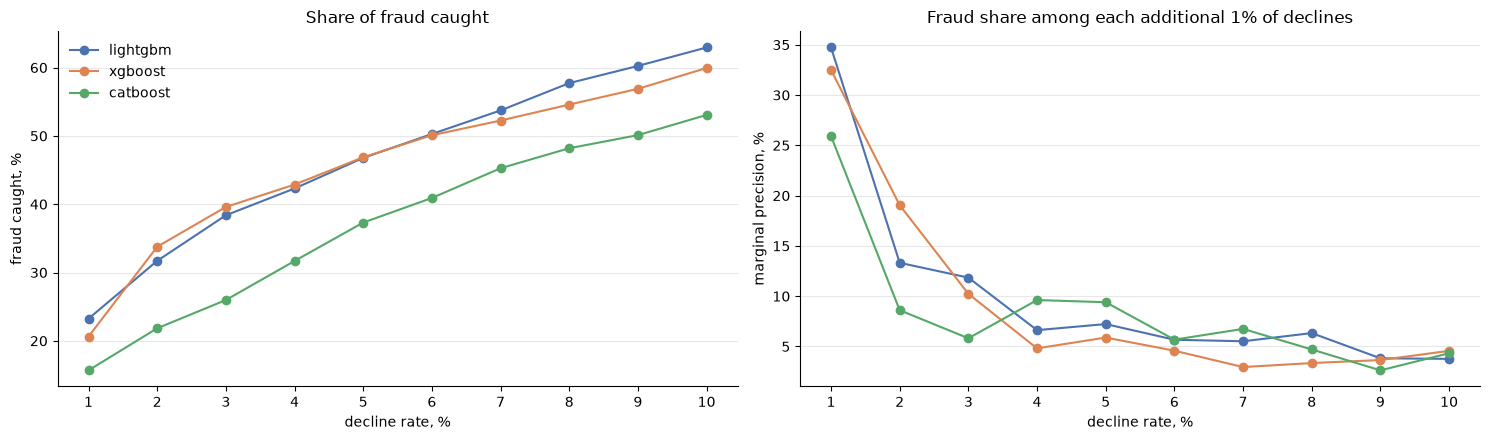

In [27]:
RATES = np.arange(1, 11)


def decline_curve(y, score, price):
    order = np.argsort(-score)
    rows, previous_k, previous_caught = [], 0, 0
    for rate in RATES:
        k = int(round(len(y) * rate / 100))
        top = order[:k]
        caught = int((y[top] == 1).sum())
        rows.append({
            "decline_%": rate,
            "fraud_caught_%": caught / y.sum() * 100,
            "precision_%": caught / k * 100,
            "marginal_precision_%": (caught - previous_caught) / (k - previous_k) * 100,
            "value_caught_%": price[top][y[top] == 1].sum() / price[y == 1].sum() * 100,
        })
        previous_k, previous_caught = k, caught
    return pd.DataFrame(rows).set_index("decline_%")


train_curves = {name: pd.concat([decline_curve(*fold) for fold in scores]).groupby(level=0).mean()
                for name, scores in fold_scores.items()}

for metric in ["fraud_caught_%", "precision_%", "marginal_precision_%", "value_caught_%"]:
    display(pd.DataFrame({name: curve[metric] for name, curve in train_curves.items()})
            .round(1).rename_axis(f"{metric} by decline %, validation months"))

COLORS = {"lightgbm": "#4C72B0", "xgboost": "#DD8452", "catboost": "#55A868"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, color in COLORS.items():
    axes[0].plot(RATES, train_curves[name]["fraud_caught_%"], marker="o", color=color, label=name)
    axes[1].plot(RATES, train_curves[name]["marginal_precision_%"], marker="o", color=color, label=name)
axes[0].set(title="Share of fraud caught", xlabel="decline rate, %", ylabel="fraud caught, %")
axes[1].set(title="Fraud share among each additional 1% of declines", xlabel="decline rate, %", ylabel="marginal precision, %")
for ax in axes:
    ax.set_xticks(RATES)
    ax.grid(axis="y", alpha=.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Results.**

1. **XGBoost catches the most fraud from 2% to 5%:** 33.8% at 2%, 39.6% at 3% and 46.9% at 5%. LightGBM is slightly ahead at 1% (23.2% and 20.6%) and from 6% to 10%; CatBoost is behind at every level (21.8% at 2%). So the selected model is the best exactly in the zone the business cares about.

2. **The share of fraud among the rejected on XGBoost is 32.5% at 1%, 25.8% at 2% and 14.5% at 5%.** The more we reject, the more legitimate buyers there are among the rejected.

3. **The marginal precision drops sharply after 2%:** 32.5% of the first 1% of rejections on XGBoost is fraud, 19.0% of the second, 10.2% of the third and only 4.8% of the fourth. So the zone of useful rejection is the first 2 to 3 percent; after 3% we reject about 16 to 32 legitimate buyers for every additional fraud caught.

4. **By value** XGBoost and LightGBM are the same: at 2% they catch 36.3% and 36.4% of the value of fraud, so both catch fraud that is more expensive than average.

These curves are the basis for choosing the threshold, which we do in the next part.

### 4.8 More complex features that we would try at the next stage

In this version each transaction is scored on its own. The next step is the context of the user and of the traffic. All of them have to be computed only from past events, so that we do not introduce leakage.

1. **User behavior:** the number of attempts and rejections in the last 1 and 24 hours, the time since the previous attempt, the number of different cards. The exploration showed that the rejected attempts of users with chargebacks pile up around the moment of fraud, so this is exactly what should be captured.
2. **Attack detection:** a sudden rise in the sales of the same product, country or issuer in the last hours, compared to the baseline level. Fraud comes in waves, so a signal that a wave is starting is valuable.
3. **Local hour** in the time zone of the buyer's country, which solves the problem of the UTC hour.
4. **Interactions as separate features:** issuer and country, account age and product type, price and payment method.
5. **Time-decayed target encoding**, where the last weeks have more weight, because the risk of products and issuers changes quickly.
6. **New data that we do not have right now** and that is especially relevant for new customers: the card fingerprint (BIN and card identifier), the device identifier, the risk of the IP (proxy and VPN), the match between the email and the cardholder name, the age of the email.

## 5. Evaluation and production

### 5.1 Final model

We train the selected model on all of train: we fit the encoder on all of train, and take the median of the validation folds as the number of trees.

In [28]:
import joblib

full_state, X_train_enc = fit_encoder(X_train, y_train)
X_test_enc = transform(full_state, X_test)
X_fit, X_eval = (X_train, X_test) if CHOSEN == "catboost" else (X_train_enc, X_test_enc)
FINAL_TREES = int(np.median(tuned_iterations[CHOSEN]))
final_model, _ = train_model(CHOSEN, best_params[CHOSEN], X_fit, y_train, n_estimators=FINAL_TREES)
score = final_model.predict_proba(X_eval)[:, 1]
print(f"Final model: {CHOSEN}, trees: {FINAL_TREES}, trained on {len(y_train):,} transactions")

Final model: xgboost, trees: 518, trained on 166,278 transactions


### 5.2 Choosing the optimal threshold

We choose the threshold on train and do not touch the test. The threshold has to be set on the probability of the final model, because that is what will run in production. For this we need the scores of the final model on transactions it has not seen. The method consists of three steps.

**Step 1: scores by cross-fitting.** We split the period from February to April into 15 consecutive blocks, each about 6 days. Each block is scored by a model that was trained on all of train except this block, with the same parameters and number of trees as the final model. This way the score of each transaction comes from a model that has not seen this transaction, and at the same time it is on the scale of the final model. We do not use January for choosing the threshold, because its fraud rate is untypically low. For comparison we show two alternatives: the scores of the final model on the same transactions it was trained on, and the scores from 4.7, where each month is scored by a model trained on the previous months.

In [29]:
EVAL_MONTHS = {2: "Feb", 3: "Mar", 4: "Apr"}
CROSS_FIT_BLOCKS = 15

eval_idx = np.where(np.isin(month_train, list(EVAL_MONTHS)))[0]
cross_fit = np.zeros(len(y_train))
for block in np.array_split(eval_idx, CROSS_FIT_BLOCKS):
    rest = np.setdiff1d(np.arange(len(y_train)), block)
    if CHOSEN == "catboost":
        X_rest, X_block = X_train.iloc[rest], X_train.iloc[block]
    else:
        block_state, X_rest = fit_encoder(X_train.iloc[rest], y_train[rest])
        X_block = transform(block_state, X_train.iloc[block])
    block_model, _ = train_model(CHOSEN, best_params[CHOSEN], X_rest, y_train[rest], n_estimators=FINAL_TREES)
    cross_fit[block] = block_model.predict_proba(X_block)[:, 1]

y_eval, price_eval, month_eval = y_train[eval_idx], price_train[eval_idx], month_train[eval_idx]
candidates = {
    "final model on its own training rows": final_model.predict_proba(X_fit)[:, 1][eval_idx],
    "cross fitted, final model scale": cross_fit[eval_idx],
    "previous months model": np.concatenate([fold[1] for fold in fold_scores[CHOSEN]]),
}
summary = {}
for name, candidate in candidates.items():
    top = np.argsort(-candidate)[:int(round(len(candidate) * 0.02))]
    row = {"pr_auc": average_precision_score(y_eval, candidate), "fraud among top 2% %": y_eval[top].mean() * 100,
           "mean predicted %": candidate.mean() * 100, "actual fraud %": y_eval.mean() * 100}
    row.update({f"98th percentile {label}": np.quantile(candidate[month_eval == m], 0.98) for m, label in EVAL_MONTHS.items()})
    summary[name] = row
display(pd.DataFrame(summary).T.round(4))

,pr_auc,fraud among top 2% %,mean predicted %,actual fraud %,98th percentile Feb,98th percentile Mar,98th percentile Apr
final model on its own training rows,0.6870,55.1471,1.4844,1.5343,0.0658,0.3922,0.1289
"cross fitted, final model scale",0.3608,36.3154,1.4701,1.5343,0.1875,0.1462,0.1251
previous months model,0.2106,23.5703,0.7137,1.5343,0.0085,0.0697,0.0726


**Results.**

1. **The scores of the final model on the same transactions it was trained on are very optimistic:** PR AUC 0.687, and the fraud rate in the riskiest 2% is 55.1%. A threshold and a calibration chosen on them would overstate the real ability of the model, so we do not use them.

2. **The scores of the models trained on the previous months are honest, but they are on a different scale:** the 98th percentile changes from month to month from 0.0085 to 0.0726, because each month is scored by a different model. A threshold set on these scores does not fit the final model: the same number would give a completely different rejection rate on it.

3. **The cross-fitted scores solve both problems.** They are on the scale of the final model (98th percentile from 0.125 to 0.188) and on average almost match the real rate (1.47% and 1.53%). Their PR AUC (0.361) is higher than that of the previous months model (0.211), because neighboring blocks share fraud waves. So we use these scores only for the threshold and the calibration, and we evaluate the quality of the model on the test.

**Step 2: calibration and diminishing marginal effect.** We fit Platt's method on the cross-fitted scores (a logistic regression on the logit of the score), so that the score becomes a real probability of fraud. Platt has only two parameters and is stable even on a small number of fraud cases; isotonic would overfit on this volume. The calibration does not change the order of the transactions, it only gives the threshold a business meaning.

Then we sort the transactions by risk and raise the rejection rate from 1% to 10%. For each additional 1% we compute what share of it is fraud, how much loss it saves us and how many legitimate orders it blocks for nothing. We do not combine the two amounts into one number, because for that we would need to know the company's margin and the cost of losing a customer, which are not in the data.

Platt calibration: logit(p) = -0.335 + 0.854 * logit(score)
Mean calibrated probability 1.54%   actual fraud rate 1.53%


,probability threshold %,fraud caught %,fraud among declined %,fraud in the added 1% %,loss avoided per month,good amount blocked per month,added 1%: loss avoided per month,added 1%: good amount blocked per month
"decline %, Feb to Apr",,,,,,,,
1,25.9,32.7,50.2,50.2,8650.0,9802.7,8650.0,9802.7
2,13.9,47.3,36.3,22.4,12751.2,26224.7,4101.1,16422.0
3,9.6,55.2,28.2,12.0,14960.6,45222.3,2209.4,18997.7
4,7.2,59.8,22.9,7.1,16358.1,64768.8,1397.5,19546.4
5,5.6,62.4,19.1,3.9,17186.1,83882.7,828.0,19114.0
6,4.6,65.0,16.6,4.0,17823.1,102717.3,637.0,18834.6
7,3.9,66.2,14.5,2.0,18118.3,121313.0,295.2,18595.7
8,3.3,68.0,13.0,2.7,18714.3,139251.4,596.1,17938.3
9,2.9,69.2,11.8,1.9,18967.1,156688.8,252.8,17437.4


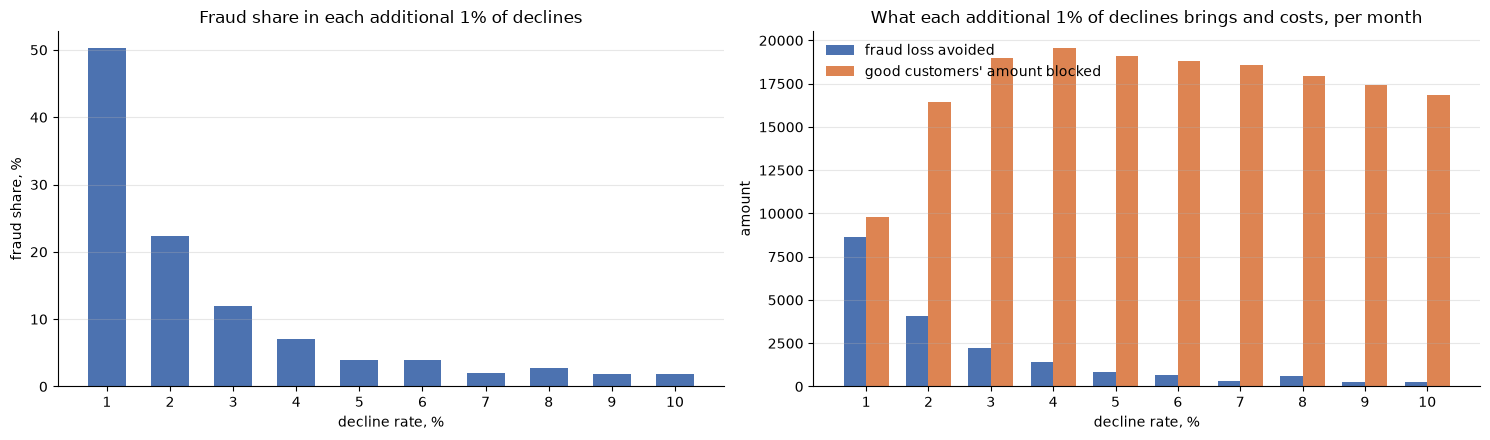

In [30]:
from sklearn.linear_model import LogisticRegression


def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


calibrator = LogisticRegression(C=1e6).fit(to_logit(cross_fit[eval_idx]), y_eval)


def calibrate(raw_score):
    return calibrator.predict_proba(to_logit(raw_score))[:, 1]


probability_eval = calibrate(cross_fit[eval_idx])
print(f"Platt calibration: logit(p) = {calibrator.intercept_[0]:.3f} + {calibrator.coef_[0, 0]:.3f} * logit(score)")
print(f"Mean calibrated probability {probability_eval.mean():.2%}   actual fraud rate {y_eval.mean():.2%}")

order = np.argsort(-probability_eval)
rows, previous = [], {"k": 0, "caught": 0, "avoided": 0.0, "blocked": 0.0}
for rate in RATES:
    k = int(round(len(order) * rate / 100))
    top = order[:k]
    is_fraud = y_eval[top] == 1
    current = {"k": k, "caught": int(is_fraud.sum()), "avoided": price_eval[top][is_fraud].sum(),
               "blocked": price_eval[top][~is_fraud].sum()}
    rows.append({
        "decline %": rate,
        "probability threshold %": probability_eval[top].min() * 100,
        "fraud caught %": current["caught"] / y_eval.sum() * 100,
        "fraud among declined %": current["caught"] / k * 100,
        "fraud in the added 1% %": (current["caught"] - previous["caught"]) / (k - previous["k"]) * 100,
        "loss avoided per month": current["avoided"] / len(EVAL_MONTHS),
        "good amount blocked per month": current["blocked"] / len(EVAL_MONTHS),
        "added 1%: loss avoided per month": (current["avoided"] - previous["avoided"]) / len(EVAL_MONTHS),
        "added 1%: good amount blocked per month": (current["blocked"] - previous["blocked"]) / len(EVAL_MONTHS),
    })
    previous = current
tradeoff = pd.DataFrame(rows).set_index("decline %")
display(tradeoff.round(1).rename_axis("decline %, Feb to Apr"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(tradeoff.index, tradeoff["fraud in the added 1% %"], width=.6, color="#4C72B0")
axes[0].set(title="Fraud share in each additional 1% of declines", xlabel="decline rate, %", ylabel="fraud share, %")
width = .36
axes[1].bar(tradeoff.index - width / 2, tradeoff["added 1%: loss avoided per month"], width,
            color="#4C72B0", label="fraud loss avoided")
axes[1].bar(tradeoff.index + width / 2, tradeoff["added 1%: good amount blocked per month"], width,
            color="#DD8452", label="good customers' amount blocked")
axes[1].set(title="What each additional 1% of declines brings and costs, per month",
            xlabel="decline rate, %", ylabel="amount")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks(RATES)
    ax.grid(axis="y", alpha=.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Results.**

1. **After calibration** the average probability is 1.54% and the actual fraud rate is 1.53%.

2. **The diminishing marginal effect is clear.** The fraud rate is 50.2% in the first 1% of rejections, 22.4% in the second, 12.0% in the third, 7.1% in the fourth, and about 4% or less from the fifth on. So the first rejections are right almost half of the time, and then it gets worse quickly.

3. **In amounts, on average per month:** the first 1% saves us a loss of 8,650 and blocks 9,803 for nothing, almost one to one. The second 1% saves 4,101 at a cost of 16,422, the third only 2,209 at a cost of 18,998, and the fifth 828 at a cost of 19,114. From the second 1% on, the amount blocked for nothing is almost unchanged at every step, while the loss avoided disappears quickly.

4. **We choose 2%.** Up to 2%, in each additional 1% at least one in five transactions is fraud, and in total we catch 47.3% of fraud. From the third 1% on, 88% of the rejected are legitimate buyers and the amount blocked for nothing is 8.6 times the loss avoided. The same turning point was visible in 4.7 as well. At the 2% point the calibrated probability is 13.9%.

**Business wording:** "we reject a transaction if the probability of fraud reaches 13.9%". This rule is easy to understand, and it can be tightened or relaxed with the table above, where the gain and the cost of each step are shown in amounts.

**Step 3: threshold.** The calibrated probability of the chosen point becomes the threshold: we reject a transaction if its probability of fraud reaches this level. We check how this threshold would have worked in the months of train, and we save the model, the encoder, the calibration and the threshold in one file.

In [31]:
CHOSEN_RATE = 2
P_STAR = float(probability_eval[order[:int(round(len(order) * CHOSEN_RATE / 100))]].min())

declined_eval = probability_eval >= P_STAR
display(pd.DataFrame({
    "fraud %": pd.Series(y_eval).groupby(month_eval).mean() * 100,
    "declined %": pd.Series(declined_eval).groupby(month_eval).mean() * 100,
    "fraud among declined %": pd.Series(y_eval[declined_eval]).groupby(month_eval[declined_eval]).mean() * 100,
}).rename(index=EVAL_MONTHS).round(2).rename_axis(f"probability threshold {P_STAR:.2%}"))

ARTIFACTS_PATH = ROOT / "data" / "processed" / "fraud_model.joblib"
ARTIFACTS_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": final_model, "name": CHOSEN, "encoder_state": full_state, "params": best_params[CHOSEN],
             "calibrator": calibrator, "probability_threshold": P_STAR}, ARTIFACTS_PATH)
print(f"Decline when the calibrated fraud probability is at least {P_STAR:.2%}")

,fraud %,declined %,fraud among declined %
probability threshold 13.93%,,,
Feb,1.20,2.40,33.61
Mar,2.01,1.98,42.11
Apr,1.37,1.63,33.03


Decline when the calibrated fraud probability is at least 13.93%


**Results.** With the 13.93% threshold, 2.40% would have been rejected in February, 1.98% in March and 1.63% in April across the train months, and the fraud rate among the rejected is between 33.0% and 42.1%.

Note that the rejection rate changes from month to month. This is a desirable property of a fixed probability threshold: the model rejects more when there really are more risky transactions in the traffic, and less in a calm period. A fixed rejection rate, on the contrary, would block the same number during an attack too.

### 5.3 What would have happened in production: the test period

So far we have not touched the test. Now we apply the final model, the calibration and the threshold to it the way it would work in production: every transaction whose calibrated probability of fraud reaches the threshold is rejected. The threshold stays unchanged over the whole period. We also look at the result by week and at the end compare with the existing approach: the transactions that the existing system let through, without the model and with the model.

In [32]:
fraud = y_test == 1
probability = calibrate(score)
declined = probability >= P_STAR
display(pd.Series(evaluate(y_test, score, price_test)).round(4).to_frame(f"{CHOSEN}, test"))

display(pd.Series({
    "declined transactions": int(declined.sum()),
    "declined %": declined.mean() * 100,
    "fraud among declined %": fraud[declined].mean() * 100,
    "fraud caught": int((declined & fraud).sum()),
    "fraud caught %": (declined & fraud).sum() / fraud.sum() * 100,
    "fraud value caught %": price_test[declined & fraud].sum() / price_test[fraud].sum() * 100,
    "good customers declined": int((declined & ~fraud).sum()),
    "good customers declined %": (declined & ~fraud).sum() / (~fraud).sum() * 100,
    "fraud loss avoided": price_test[declined & fraud].sum(),
    "good customers' amount blocked": price_test[declined & ~fraud].sum(),
}).round(2).to_frame(f"fixed threshold: probability of at least {P_STAR:.2%}"))

test_week = ((test_rows["ts"] - TEST_START).dt.days // 7).to_numpy()
weekly_frame = pd.DataFrame({
    "week starting": (TEST_START + pd.to_timedelta(test_week * 7, unit="D")).strftime("%d %b"),
    "fraud": fraud, "declined": declined,
})
weekly = weekly_frame.groupby("week starting", sort=False).agg(
    transactions=("fraud", "size"), fraud_pct=("fraud", "mean"), declined_pct=("declined", "mean"))
weekly[["fraud_pct", "declined_pct"]] *= 100
weekly["fraud among declined %"] = (weekly_frame[weekly_frame["declined"]]
                                    .groupby("week starting", sort=False)["fraud"].mean() * 100)
display(weekly.round(2))

display(pd.DataFrame({
    "current approach": {
        "transactions accepted": len(y_test), "declined by the model": 0, "chargebacks": int(fraud.sum()),
        "chargeback rate %": fraud.mean() * 100, "fraud value lost": price_test[fraud].sum(),
        "good customers declined": 0, "good customers' amount blocked": 0},
    "current approach + model": {
        "transactions accepted": int((~declined).sum()), "declined by the model": int(declined.sum()),
        "chargebacks": int((fraud & ~declined).sum()), "chargeback rate %": fraud[~declined].mean() * 100,
        "fraud value lost": price_test[fraud & ~declined].sum(),
        "good customers declined": int((declined & ~fraud).sum()),
        "good customers' amount blocked": price_test[declined & ~fraud].sum()},
}).round(2).rename_axis("test period, 1 May to 16 June"))

,"xgboost, test"
pr_auc,0.1517
roc_auc,0.8620
brier,0.0130
recall_1%,0.1903
precision_1%,0.2710
value_caught_1%,0.1887
recall_2%,0.3056
precision_2%,0.2176
value_caught_2%,0.3367
recall_5%,0.4464


,fixed threshold: probability of at least 13.93%
declined transactions,671.00
declined %,1.28
fraud among declined %,24.74
fraud caught,166.00
fraud caught %,22.25
fraud value caught %,23.26
good customers declined,505.00
good customers declined %,0.98
fraud loss avoided,8448.62
good customers' amount blocked,49019.85


,transactions,fraud_pct,declined_pct,fraud among declined %
week starting,,,,
01 May,10006,1.17,1.27,15.75
08 May,8169,2.09,1.90,44.52
15 May,7094,1.49,1.18,26.19
22 May,7749,0.97,0.86,19.40
29 May,7653,1.27,1.42,17.43
05 Jun,6813,1.09,1.01,17.39
12 Jun,4912,2.16,1.22,18.33


,current approach,current approach + model
"test period, 1 May to 16 June",,
transactions accepted,52396.00,51725.00
declined by the model,0.00,671.00
chargebacks,746.00,580.00
chargeback rate %,1.42,1.12
fraud value lost,36327.23,27878.61
good customers declined,0.00,505.00
good customers' amount blocked,0.00,49019.85


**Results.**

1. **Model quality on the test:** PR AUC 0.152, ROC AUC 0.862. Compared to a random model this is about 11 times better, because the fraud rate in the test is 1.42%. The riskiest 2% by score contain 30.6% of the fraud in the test.

2. **With the 13.93% threshold on the test:**
   1. 671 transactions are rejected, or 1.28%;
   2. **24.7% of the rejected are really fraud**, about one in four;
   3. 166 of 746 fraud cases are caught (22.3%) and 23.3% of the value of fraud;
   4. 505 legitimate buyers are rejected, or 0.98%.

3. **Why 1.28% and not 2%.** We set the 2% point on the cross-fitted scores of train, which are slightly optimistic. On new months the model is less confident and fewer transactions have a probability above 13.9%. The threshold itself works correctly: the average calibrated probability of the rejected transactions is 24.9% and in fact 24.7% of them are fraud. So the model rejects only what is really risky enough and does not block for nothing.

4. **By week** the rejection rate changes from 0.86% to 1.90%. The model rejects the most in the week of 8 May (1.90%), when the fraud rate is also high (2.09%), and in that week 44.5% of the rejected are fraud. So the threshold tightens by itself during an attack. In the week of 12 June, however, despite the high fraud rate (2.16%) only 1.22% is rejected: the model does not recognize part of the fraud of that week, which shows the need for regular retraining.

5. **Comparison with the existing approach.** The model is added on top of the existing system and scores only the transactions that the system has already let through. In the test period:
   1. **the number of chargebacks goes down from 746 to 580 (by 22%)**, and the chargeback rate among accepted transactions from 1.42% to 1.12%;
   2. **the value lost to fraud goes down from 36,327 to 27,879 (by 23%), so we avoid a loss of 8,449**;
   3. the cost: 505 legitimate buyers rejected out of 51,725 accepted transactions, a total of 49,020 in orders blocked for nothing.

### 5.4 New and returning customers

With the chosen threshold we check how the model works on customers who already appeared in train and on new customers.

In [33]:
returning = test_rows["userId"].isin(train_rows["userId"]).to_numpy()
segments = []
for label, mask in [("returning customers", returning), ("new customers", ~returning)]:
    y_seg, flagged = y_test[mask], declined[mask]
    segments.append({"segment": label, "transactions": int(mask.sum()), "fraud": int(y_seg.sum()),
                     "declined %": flagged.mean() * 100,
                     "fraud among declined %": (y_seg[flagged] == 1).mean() * 100,
                     "fraud caught %": (flagged & (y_seg == 1)).sum() / y_seg.sum() * 100})
display(pd.DataFrame(segments).set_index("segment").round(2))

,transactions,fraud,declined %,fraud among declined %,fraud caught %
segment,,,,,
returning customers,8649,55,0.57,30.61,27.27
new customers,43747,691,1.42,24.28,21.85


**Results.** The model rejects only 0.57% of the returning customers and 30.6% of these rejections are fraud; 27.3% of their fraud is caught. Among new customers 1.42% are rejected, the fraud rate among the rejected is 24.3% and 21.9% of their fraud is caught.

Two conclusions:

1. **The largest part of fraud comes from new customers** (691 of 746), where we have no history. This is exactly where user behavior and device features will be the most useful.
2. **The model rarely bothers returning customers**, and it is also more precise on them. This is good for the user experience: loyal customers are almost not affected.

### 5.5 What drives the decision of the model

We compute SHAP values on 5,000 random transactions from the test. On the plot each dot is one transaction: the horizontal position shows how much the feature raises (to the right) or lowers (to the left) the fraud score, and the color shows the value of the feature: red is high, blue is low.

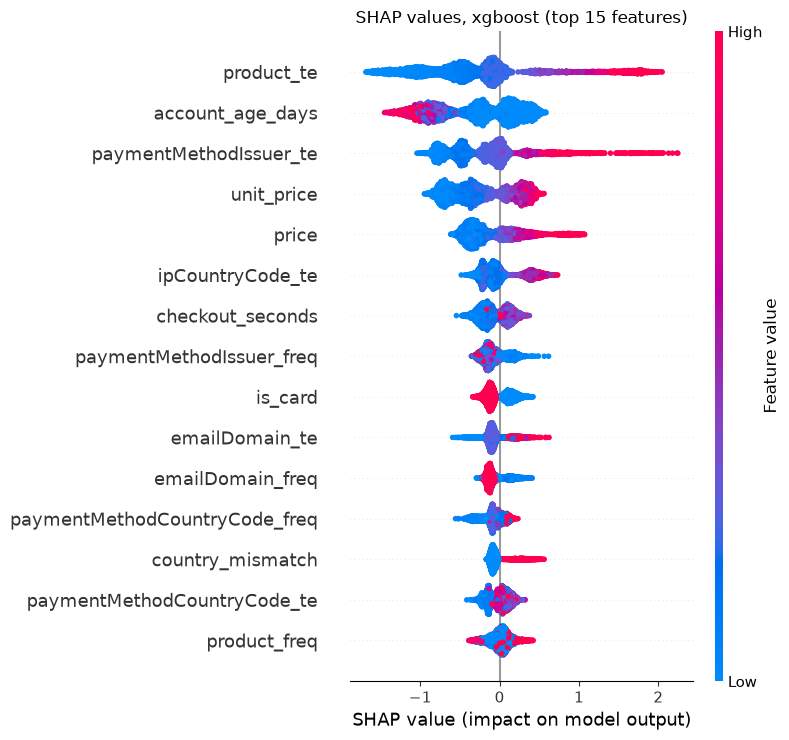

,share of top 15 %
product_te,17.6
account_age_days,13.4
paymentMethodIssuer_te,11.6
unit_price,11.4
price,8.5
ipCountryCode_te,5.6
checkout_seconds,4.6
paymentMethodIssuer_freq,4.0
is_card,4.0
emailDomain_te,3.7


In [34]:
import shap

sample = np.random.default_rng(0).choice(len(y_test), 5000, replace=False)
if CHOSEN == "catboost":
    X_sample = X_test.iloc[sample]
    shap_values = final_model.get_feature_importance(Pool(X_sample, cat_features=CAT_FEATURES), type="ShapValues")[:, :-1]
else:
    X_sample = X_test_enc.iloc[sample]
    shap_values = shap.TreeExplainer(final_model).shap_values(X_sample)
    shap_values = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(shap_values, X_sample, max_display=15, show=False)
plt.title(f"SHAP values, {CHOSEN} (top 15 features)")
plt.tight_layout()
plt.show()

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_sample.columns).sort_values(ascending=False).head(15)
display((importance / importance.sum() * 100).round(1).to_frame("share of top 15 %"))

**Results.**

1. **What raises the risk** (red dots on the right): a product that often had fraud before; an issuer that often had fraud before; a high unit price and an expensive order; a risky IP country and email domain; country mismatch.

2. **What lowers the risk** (red dots on the left): an old account, paying by card compared to PayPal, a popular issuer and a frequent email domain.

3. **By contribution** the most important are the product (17.6% of the top 15), account age (13.4%), the issuer (11.6%), the unit price (11.4%) and the price (8.5%). So the model relies exactly on the signals that turned out to be stable in the exploration.

4. **The signals that depend on the wave are weakly represented:** country mismatch is only 3.1% of the top 15, and the day of the week is not in the top 15 at all. This is a good sign: regularization and time-based validation prevented too much reliance on the traces of the wave.

5. **The contribution of checkout duration is 4.6%**, so the model does not depend on it much. We check this separately in 5.7.

### 5.6 Calibration on the test

The threshold is set on the calibrated probability, so we check how well this probability matches the real fraud rate on the test. We split the transactions into ten equal groups by score and in each one compare the raw score of the model, the calibrated probability and the actual fraud rate.

In [35]:
decile = pd.qcut(score, 10, labels=False, duplicates="drop") + 1
calibration = pd.DataFrame({"decile": decile, "raw": score, "calibrated": probability, "actual": y_test}).groupby("decile").agg(
    transactions=("actual", "size"), raw_score_pct=("raw", "mean"),
    calibrated_pct=("calibrated", "mean"), actual_fraud_pct=("actual", "mean"))
calibration[["raw_score_pct", "calibrated_pct", "actual_fraud_pct"]] *= 100
display(calibration.round(3))
print(f"Mean raw score {score.mean():.2%}   mean calibrated probability {probability.mean():.2%}   "
      f"actual fraud rate {y_test.mean():.2%}")
print(f"Brier score: raw {brier_score_loss(y_test, score):.4f}   calibrated {brier_score_loss(y_test, probability):.4f}   "
      f"constant prediction {y_test.mean() * (1 - y_test.mean()):.4f}")
print(f"Declined transactions: mean calibrated probability {probability[declined].mean():.2%}   "
      f"actual fraud {fraud[declined].mean():.2%}")

,transactions,raw_score_pct,calibrated_pct,actual_fraud_pct
decile,,,,
1,5240,0.024,0.057,0.019
2,5240,0.049,0.106,0.076
3,5239,0.075,0.153,0.134
4,5240,0.110,0.211,0.229
5,5239,0.158,0.288,0.458
6,5240,0.232,0.401,0.630
7,5239,0.359,0.581,0.859
8,5240,0.613,0.915,1.240
9,5239,1.332,1.766,2.424


Mean raw score 1.11%   mean calibrated probability 1.24%   actual fraud rate 1.42%
Brier score: raw 0.0130   calibrated 0.0129   constant prediction 0.0140
Declined transactions: mean calibrated probability 24.93%   actual fraud 24.74%


**Results.**

1. **Where we make the decision, the probabilities are accurate.** On the rejected transactions the average calibrated probability is 24.93% and the actual fraud rate is 24.74%. In the riskiest decile it is 7.97% and 8.17%. So the calibration learned on train carries over to the test and the threshold has a real meaning.

2. **The calibration raised the probabilities of low and medium risk and brought them closer to reality:** for example, in the fifth decile the raw score is 0.16%, the calibrated probability is 0.29% and the actual rate is 0.46%; the average probability rose from 1.11% to 1.24% (the actual is 1.42%). In the middle deciles the risk is still underestimated, but this does not affect the threshold, because these transactions are far below it.

3. **The ranking is correct:** the real fraud rate grows consistently with the score, from 0.02% to 8.17%. The Brier score went down from 0.0130 to 0.0129, and that of a constant prediction is 0.0140.

### 5.7 How much the model depends on the `eventTimestamp` assumption

In 4.1 we assumed that `eventTimestamp` is written before the decision. If this does not hold, `checkout_seconds` contains the duration of the decision process and using it would be leakage. We measure what would change in that case: we remove `checkout_seconds`, compute account age from the creation time of the order (`txId`) and take the day of the week from there as well. The rest of the procedure is unchanged: the same parameters, the same time-based CV, the same final training and one evaluation on the test.

In [36]:
def prepare_without_event_time(frame):
    out = prepare(frame).drop(columns=["checkout_seconds"])
    out["account_age_days"] = ((frame["tx_created"] - frame["user_created"]).dt.total_seconds() / 86400).to_numpy()
    out["weekday"] = frame["tx_created"].dt.day_name().to_numpy()
    return out


X_train_alt, X_test_alt = prepare_without_event_time(train_rows), prepare_without_event_time(test_rows)
alt_rows, alt_iterations = [], []
for fit_idx, val_idx in FOLDS:
    alt_state, X_fit_alt = fit_encoder(X_train_alt.iloc[fit_idx], y_train[fit_idx])
    X_val_alt = transform(alt_state, X_train_alt.iloc[val_idx])
    alt_model, best = train_model(CHOSEN, best_params[CHOSEN], X_fit_alt, y_train[fit_idx], X_val_alt, y_train[val_idx])
    alt_rows.append(evaluate(y_train[val_idx], alt_model.predict_proba(X_val_alt)[:, 1], price_train[val_idx]))
    alt_iterations.append(best)
alt_cv = pd.DataFrame(alt_rows, index=FOLD_MONTHS)

alt_state, X_fit_alt = fit_encoder(X_train_alt, y_train)
alt_final, _ = train_model(CHOSEN, best_params[CHOSEN], X_fit_alt, y_train, n_estimators=int(np.median(alt_iterations)))
alt_test = evaluate(y_test, alt_final.predict_proba(transform(alt_state, X_test_alt))[:, 1], price_test)

main_cv = tuned_cv[CHOSEN]
main_test = evaluate(y_test, score, price_test)
display(pd.DataFrame({
    "with eventTimestamp": {"cv pr_auc mean": main_cv["pr_auc"].mean(), "cv pr_auc Apr": main_cv.loc["Apr", "pr_auc"],
                            "test pr_auc": main_test["pr_auc"], "test roc_auc": main_test["roc_auc"],
                            "test fraud caught at 2% %": main_test["recall_2%"] * 100},
    "without eventTimestamp": {"cv pr_auc mean": alt_cv["pr_auc"].mean(), "cv pr_auc Apr": alt_cv.loc["Apr", "pr_auc"],
                               "test pr_auc": alt_test["pr_auc"], "test roc_auc": alt_test["roc_auc"],
                               "test fraud caught at 2% %": alt_test["recall_2%"] * 100},
}).round(4))

,with eventTimestamp,without eventTimestamp
cv pr_auc mean,0.2018,0.2050
cv pr_auc Apr,0.1570,0.1467
test pr_auc,0.1517,0.1245
test roc_auc,0.8620,0.8510
test fraud caught at 2% %,30.5630,27.0777


**Results.**

1. **On the time-based validation the two variants are practically equal:** an average PR AUC of 0.202 and 0.205, so it is even slightly better without `checkout_seconds`.

2. **On the test a difference appears:** PR AUC 0.152 and 0.125, and fraud caught at 2% rejection 30.6% and 27.1%. So the assumption improves the result, but even without it the model is about 9 times better than random and does the business task.

3. **Conclusion.** The model does not depend critically on this assumption, which SHAP also confirms: `checkout_seconds` is only 4.6% of the top 15. Even so, the moment when `eventTimestamp` is written has to be clarified with the data owner before going to production. If it turns out that it is written after the decision, the variant shown in this part is already ready.

### 5.8 Conclusions

1. **Model: XGBoost.** On the time-based validation it is the best by the total rank over four criteria: it is the most stable between months, catches the most fraud at 2% rejection and has the most accurate probabilities. On the test the PR AUC is 0.152, about 11 times better than random.

2. **Threshold: a calibrated fraud probability of 13.9%.** We chose the threshold on train only, on the cross-fitted scores of the final model, by the diminishing marginal effect: up to 2%, in each additional 1% of rejections at least one in five transactions is fraud, while from the third 1% on 88% of the rejected are legitimate buyers.

3. **What would have happened in production (the test period):** 1.28% of transactions are rejected and 24.7% of the rejected are really fraud. There are 22% fewer chargebacks (from 746 to 580), the chargeback rate falls from 1.42% to 1.12%, and the value lost to fraud goes down by 23%, so we avoid a loss of 8,449. The cost is the rejection of 0.98% of legitimate buyers, a total of 49,020 in orders blocked for nothing.

4. **What drives the risk:** the specific product, account age, the card issuer and the price of the order. These are signals that are stable over time.

5. **Limitations:**
   1. On the rejected traffic (37.93% of all transactions) we cannot measure the quality of the model, because the outcome is never visible there.
   2. `checkout_seconds` and account age rely on the `eventTimestamp` assumption; its effect is measured in 5.7 and is small, but it needs to be clarified.
   3. The label relies on a 60 day window, which is not ground truth.

## 6. Recommendations for production

1. **Rollout in stages.** First we check that the distribution of scores and the rejection rate match the result on the test. Then we start rejecting with the 13.9% threshold on part of the traffic and compare the result with the existing rules (A/B test).

2. **The threshold and how to manage it.** The threshold is a fixed calibrated probability. If the business wants to catch more fraud, the threshold should be lowered according to the table in 5.2, where the gain and the cost of each additional 1% of rejections are shown in amounts. The decision belongs to the business, because it involves the margin, the chargeback fee, the thresholds of the payment networks and the cost of a lost customer, which are not in the data.

3. **Fraud waves.** A fixed probability threshold raises rejection by itself during an attack, which we also saw on the test. But the model does not recognize a new type of attack until it has learned from it. So we have to watch the early signals: PayPal chargebacks, 57.8% of which arrive within three days, are the fastest indicator. When they grow, the threshold should be lowered temporarily.

4. **Monitoring.**
   1. Daily: the rejection rate, the distribution of scores and its change (PSI), the distribution of the main features (countries, products, issuers).
   2. Early signal: PayPal chargebacks and complaints from rejected buyers.
   3. Full result: the chargeback rate among accepted transactions and the share of fraud caught, after 60 days.
   4. Quality of rejections: a manual review of a small sample of rejected orders.

5. **Rejected traffic.** A small, random part of the rejected transactions (for example 0.5%) should be let through without a check. This way we get labels for the transactions we cannot see now and measure the real quality of the model. Or we should do reject inference.

6. **New features.** The features listed in 4.8, first of all user behavior and attack detection, because 93% of fraud comes from new customers, where we currently have the least information.

7. **Questions to clarify with the data owner.** When `eventTimestamp` is written; the change of the catalog categories (subscription); the 33 chargebacks on rejected transactions; why some cards have no issuer and why such transactions are almost always clean.